# Trabajo Práctico: Predicción de precios de casas

**Aprendizaje Automático 1**, Tecnicatura en Inteligencia Artificial
Facultad de Ciencias Exactas, Ingeniería y Agrimensura (UNR). 2026, cuatrimestre 2

**Integrantes:** Sofia Grando, Amanda Tardugno, Lucas Díaz y Facundo Ferreira

Predecimos `MEDV`, el valor mediano de las viviendas de cada barrio de Boston en
miles de dólares, usando las otras 13 variables. Como lo que queremos predecir es un número
y no una categoría, es un problema de regresión.

## Configuración del entorno

In [1]:
# Las bibliotecas que usamos en todo el notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Estilo de los gráficos y semilla fija, para que todo salga igual cada vez que corremos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.width", 200)

# Análisis descriptivo y preprocesamiento

## Carga e inspección estructural

In [3]:
# El csv está en la misma carpeta que el notebook
df = pd.read_csv("house-prices-tp.csv")
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.07151,0.0,4.49,0.0,0.449,6.121,56.8,3.7476,3.0,247.0,18.5,395.15,8.44,22.2
1,0.08265,0.0,13.92,0.0,0.437,6.127,18.4,5.5027,4.0,289.0,16.0,396.90,8.58,23.9
2,0.12816,12.5,6.07,0.0,0.409,5.885,33.0,6.4980,4.0,345.0,18.9,396.90,8.79,20.9
3,0.08873,21.0,5.64,0.0,0.439,5.963,45.7,6.8147,4.0,243.0,16.8,395.56,13.45,19.7
4,0.11432,0.0,8.56,0.0,0.520,6.781,71.3,2.8561,5.0,384.0,20.9,395.58,7.67,26.5


In [4]:
# Dimensiones y tipo de dato de cada variable
print(f"Filas: {df.shape[0]}  |  Columnas: {df.shape[1]}")
df.dtypes.to_frame("tipo")

Filas: 556  |  Columnas: 14


,tipo
CRIM,float64
ZN,float64
INDUS,float64
CHAS,float64
NOX,float64
RM,float64
AGE,float64
DIS,float64
RAD,float64
TAX,float64


In [5]:
# Chequeamos que no haya filas repetidas, que le darían peso de más a esos barrios
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")

Filas duplicadas exactas: 0


### Las variables

Según el enunciado, las 13 características de entrada y la variable a predecir son:

| Variable | Significado |
|---|---|
| `CRIM` | Tasa de criminalidad per cápita por ciudad |
| `ZN` | Proporción de terrenos residenciales zonificados para lotes de más de 25.000 pies² |
| `INDUS` | Proporción de acres de negocios no minoristas por ciudad |
| `CHAS` | Variable *dummy* del río Charles (1 si el tramo limita con el río, 0 si no) |
| `NOX` | Concentración de óxidos de nitrógeno (partes por 10 millones) |
| `RM` | Número promedio de habitaciones por vivienda |
| `AGE` | Proporción de unidades ocupadas por sus propietarios construidas antes de 1940 |
| `DIS` | Distancias ponderadas a cinco centros de empleo de Boston |
| `RAD` | Índice de accesibilidad a las autopistas radiales |
| `TAX` | Tasa de impuesto sobre la propiedad a valor completo por cada $10.000 |
| `PTRATIO` | Proporción alumno-maestro por ciudad |
| `B` | Resultado de la ecuación B = 1000(Bk − 0,63)², con Bk la proporción de negros por ciudad |
| `LSTAT` | Porcentaje de población de menor estatus socioeconómico |
| **`MEDV`** | **Valor mediano de las viviendas, en miles de dólares, variable a predecir** |

Todas las columnas entraron como numéricas, que es lo que corresponde: no hay texto ni
categorías nominales para codificar. Dos necesitan una aclaración:

- `CHAS` es una *dummy* que ya viene como 0/1, así que no hay que hacerle nada.
- `RAD` es un índice **ordinal** de accesibilidad a las autopistas, entero de 1 a 24: un
  valor más alto significa más accesibilidad. La dejamos numérica para no perder ese orden.

`B` es una variable armada a partir de la composición racial del barrio, lo que ya la vuelve
delicada de usar, y la transformación cuadrática la deja imposible de interpretar: como la
parábola está centrada en 0,63, un mismo valor de `B` corresponde a dos proporciones
distintas, una a cada lado. La dejamos porque el
enunciado la lista como característica de entrada, pero hay que tenerlo presente cuando
miremos los coeficientes.

## Análisis descriptivo

In [6]:
# Medidas de tendencia central y dispersión de todas las variables
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CRIM,533.0,5.85,13.83,0.01,0.08,0.32,4.87,88.98
ZN,534.0,13.20,24.90,0.00,0.00,0.00,20.00,100.00
INDUS,541.0,11.22,6.94,0.46,5.13,9.69,18.10,27.74
CHAS,533.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00
NOX,532.0,0.56,0.12,0.38,0.45,0.54,0.64,0.87
RM,535.0,6.29,0.78,3.56,5.88,6.21,6.64,8.78
AGE,532.0,67.63,28.46,2.90,42.28,76.50,93.82,100.00
DIS,541.0,3.94,2.26,1.13,2.11,3.34,5.40,12.13
RAD,528.0,9.70,8.68,1.00,4.00,5.00,23.63,24.00
TAX,538.0,409.58,167.69,187.00,279.00,335.00,666.00,711.00


In [7]:
# El sesgo mide la asimetría: lejos de 0 quiere decir que hay una cola larga
df.skew().sort_values(ascending=False).to_frame("sesgo").round(2)

,sesgo
CRIM,3.75
CHAS,2.87
ZN,1.96
DIS,1.08
MEDV,1.06
RAD,0.95
LSTAT,0.95
NOX,0.69
TAX,0.63
RM,0.37


### Cada variable, una por una

Las agrupamos por lo que miden, que es como se entienden mejor.

#### Las del entorno socioeconómico

- `LSTAT` (1,73 a 37,97, mediana 11,46) es el porcentaje de población de menor estatus
  socioeconómico. Se reparte de forma bastante continua, con sesgo positivo suave (0,95):
  hay más barrios acomodados que muy pobres, pero no hay saltos.
- `CRIM` (0,01 a 88,98, mediana 0,32) es la más extrema de todas, con sesgo 3,75. La mediana
  en 0,32 contra una media de 5,85 muestra el problema: la mitad de los barrios tiene
  criminalidad casi nula y un puñado se dispara dos órdenes de magnitud.
- `B` (0,32 a 396,90, mediana 390,82) es la única con sesgo negativo fuerte (−2,40), y se
  entiende por cómo está construida: al ser una parábola centrada en 0,63, casi todos los
  barrios terminan apilados cerca del máximo.

#### Las de la vivienda

- `RM` (3,56 a 8,78, mediana 6,21) es el promedio de habitaciones. Es la más simétrica del
  conjunto (sesgo 0,37) y la que más se parece a una normal.
- `AGE` (2,90 a 100, mediana 76,50) es la proporción de viviendas anteriores a 1940. Tiene
  sesgo negativo (−0,55) y se amontona contra el 100: en la mayoría de los barrios el parque
  edilicio es viejo.
- `ZN` (0 a 100, mediana 0) es la proporción de terreno zonificado para lotes grandes. En
  372 de los 534 barrios observados vale exactamente 0, así que más que una variable
  continua se comporta como "tiene o no tiene lotes grandes" y, cuando tiene, cuántos.

#### Las del entorno urbano e industrial

- `INDUS` (0,46 a 27,74, mediana 9,69) es la proporción de suelo industrial, y es la más
  pareja de todo el conjunto (sesgo 0,30).
- `NOX` (0,38 a 0,87, mediana 0,54) mide contaminación. Rango chico en valor absoluto, pero
  el máximo más que duplica al mínimo.
- `DIS` (1,13 a 12,13, mediana 3,34) es la distancia a los centros de empleo, con sesgo 1,08:
  la mayoría de los barrios está cerca y unos pocos quedan lejos.
- `CHAS` (0 o 1) indica si el barrio linda con el río. Sólo 48 de 533 valen 1, apenas un 9%,
  así que es una variable muy desbalanceada.

#### Las institucionales

- `RAD` (1 a 24, mediana 5) es el índice de accesibilidad a autopistas. No se reparte
  continuo: 132 barrios valen exactamente 24 y el resto se concentra entre 1 y 8. Son dos
  grupos separados más que una escala gradual.
- `TAX` (187 a 711, mediana 335) es la tasa impositiva, y tiene la misma estructura partida:
  143 barrios superan los 600. Que tenga la misma forma que `RAD` hace
  sospechar que las dos van juntas.
- `PTRATIO` (12,60 a 22, mediana 19) es la relación alumno-maestro, con sesgo negativo
  (−0,79) y concentrada en la parte alta del rango.

#### La variable a predecir

- `MEDV` (5 a 50, mediana 21,20) es el precio en miles de dólares, con sesgo positivo (1,06).
  El máximo cae exactamente en 50.

### Lectura del descriptivo

Las escalas no tienen nada que ver entre sí. `TAX` va de 187 a
711 y `B` llega a 396,9, mientras que `NOX` se mueve entre 0,38 y 0,87 y `CHAS` es 0 o 1.
A mínimos cuadrados esto no le molesta, pero al gradiente descendente sí (converge mal
cuando las escalas son dispares) y a la regularización todavía más, porque la penalización
mira el tamaño del coeficiente: sin escalar castigaría más a las variables de valores
chicos sólo por la unidad en la que están medidas. Por eso hay que escalar antes de esos modelos.

Varias distribuciones son bastante asimétricas. `CRIM` tiene mediana 0,32 pero máximo 88,98:
casi todos los barrios tienen criminalidad baja y unos pocos estiran la cola. Pasa algo
parecido con `ZN` (mediana 0) y con `CHAS` (apenas el 9% de los barrios linda con el río).
En estas variables un valor extremo no es necesariamente un error de carga: puede ser un barrio
que realmente es así.

Y hay algo en `MEDV` que nos llamó la atención: llega justo hasta 50. Con mediana 21,2, que
el máximo sea un número tan redondo es raro. Si los valores altos se repartieran como en
cualquier variable continua, no habría motivo para que se corten exactamente ahí.

In [8]:
# Contamos cuántas viviendas caen justo en el máximo de la escala
tope = (df["MEDV"] == 50).sum()
print(f"Viviendas con MEDV = 50: {tope} ({tope / df['MEDV'].notna().sum():.1%} de las observadas)")

Viviendas con MEDV = 50: 16 (3.0% de las observadas)


In [9]:
# Cómo se reparten los precios más altos: si 50 fuera un valor más, no juntaría más casos que sus vecinos
cerca = df["MEDV"].between(45, 50, inclusive="left")
print(f"Entre 45 y 50, sin incluir 50: {cerca.sum()} viviendas, con {df.loc[cerca, 'MEDV'].nunique()} valores distintos")
print(f"Exactamente 50: {tope}")
print(f"Más de 50: {(df['MEDV'] > 50).sum()}")

Entre 45 y 50, sin incluir 50: 11 viviendas, con 11 valores distintos
Exactamente 50: 16
Más de 50: 0


Los precios altos se ralean de a poco: entre 45 y 50 hay 11 viviendas, cada una con un valor
distinto. Y de golpe hay 16 apiladas exactamente en 50, y ninguna por encima. Una variable
continua no se comporta así: 50 funciona como un tope, donde todo lo que valía más quedó
anotado como 50. Para el modelo significa que ahí el valor real no lo sabemos.

## Análisis y decisión sobre datos faltantes

In [10]:
# Cantidad y porcentaje de valores faltantes en cada variable
faltantes = df.isna().sum()
pd.DataFrame({"faltantes": faltantes,
              "% del total": (faltantes / len(df) * 100).round(1)})

,faltantes,% del total
CRIM,23,4.1
ZN,22,4.0
INDUS,15,2.7
CHAS,23,4.1
NOX,24,4.3
RM,21,3.8
AGE,24,4.3
DIS,15,2.7
RAD,28,5.0
TAX,18,3.2


In [11]:
# Cuántos valores le faltan a cada fila, para ver si los faltantes se concentran o no
por_fila = df.isna().sum(axis=1)
print(f"Celdas faltantes en total: {int(faltantes.sum())}")
print(f"Filas completas: {(por_fila == 0).sum()}  |  Filas con al menos un faltante: {(por_fila > 0).sum()}")
por_fila[por_fila > 0].value_counts().sort_index().to_frame("cantidad de filas").rename_axis("faltantes en la fila")

Celdas faltantes en total: 306
Filas completas: 506  |  Filas con al menos un faltante: 50


,cantidad de filas
faltantes en la fila,
1,5
2,3
3,11
4,3
5,3
6,2
7,5
8,4
9,4


### Diagnóstico

Las 306 celdas faltantes se concentran en 50 filas: las otras 506 están completas, sin un
solo valor ausente. Pero esas 50 no son todas iguales. Hay dos grupos bien distintos:

- **42 filas muy dañadas**, con 3 o más valores ausentes. En promedio les faltan 7 de sus 14
  columnas, y hay tres a las que les faltan 13 y una a la que le faltan las 14. En 21 de
  ellas lo que falta es `MEDV`, que es justo lo que hay que predecir.
- **8 filas con sólo 1 o 2 faltantes**, que conservan casi todo lo que describe al barrio y
  tienen `MEDV`.

### Primera decisión

Las 42 filas muy dañadas se descartan. A una fila a la que le faltan 7 de 14 valores no le
queda información suficiente para reconstruir lo que perdió: lo que pusiéramos describiría
al método que usemos y no al barrio. Las 21 sin `MEDV` se van igual aunque el resto esté
completo, porque `MEDV` es lo que el modelo tiene que aprender: completarla sería entrenar
contra algo que inventamos nosotros, y si alguna cayera en prueba estaríamos midiendo el
error contra un valor inventado.

Las 8 filas restantes son otra cosa. Les falta un dato o dos sobre catorce, así que en
principio se pueden recuperar y valen 8 barrios más para entrenar.

In [12]:
# Separamos los dos grupos según qué tan dañada está cada fila
faltantes_por_fila = df.isna().sum(axis=1)
muy_danadas = df[faltantes_por_fila >= 3]
recuperables = df[(faltantes_por_fila > 0) & (faltantes_por_fila <= 2)]
print(f"Muy dañadas (3 o más faltantes): {len(muy_danadas)}")
print(f"Recuperables (1 o 2 faltantes): {len(recuperables)}")

Muy dañadas (3 o más faltantes): 42
Recuperables (1 o 2 faltantes): 8


In [13]:
# Las miramos enteras, que son pocas
recuperables.round(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
14,30.99,60.71,8.83,0.0,0.75,NaN,23.59,5.06,10.55,621.33,16.63,60.16,30.49,23.68
230,23.79,67.38,21.01,0.0,0.86,8.42,70.78,5.82,17.16,NaN,20.18,370.99,9.33,24.24
264,38.61,59.56,15.55,1.0,0.59,3.84,20.30,2.90,21.90,593.20,NaN,123.45,3.39,48.85
316,46.64,29.09,23.68,1.0,0.72,4.59,NaN,3.70,NaN,525.19,17.61,208.32,9.80,38.72
327,76.76,17.44,26.40,1.0,0.63,7.55,41.84,6.35,3.06,504.22,20.90,NaN,12.24,46.19
348,79.41,98.46,20.95,1.0,0.43,5.62,44.30,5.88,NaN,445.47,20.61,384.91,27.39,28.06
538,NaN,51.83,21.76,0.0,0.82,4.93,9.77,9.98,14.20,344.02,NaN,312.77,9.37,45.85
554,32.50,6.53,8.94,1.0,NaN,4.02,NaN,5.24,20.42,197.24,19.64,6.27,7.03,23.03


Mirándolas de cerca hay algo que no cuadra. `RAD` es un índice entero de 1 a 24, y acá
aparece en 10,55; 17,16; 21,90; 3,06; 14,20 y 20,42. `TAX` es una tasa impositiva que en el
resto del archivo viene en valores redondos, y acá da 621,33; 593,20; 525,19. Ninguno de los
dos debería tener decimales.

Si esos valores no son los que tendría un barrio real, entonces el problema de estas filas
no es lo que les falta sino lo que tienen.

In [14]:
# Comparamos cuántos valores con decimales hay en cada grupo, para las columnas que deberían ser enteras
completas = df.dropna()
enteras = ["RAD", "TAX", "CHAS"]
pd.DataFrame({
    "recuperables: con decimales": [(recuperables[c].dropna() % 1 != 0).sum() for c in enteras],
    "recuperables: valores presentes": [recuperables[c].notna().sum() for c in enteras],
    "completas: con decimales": [(completas[c] % 1 != 0).sum() for c in enteras],
    "completas: valores presentes": [len(completas)] * len(enteras),
}, index=enteras)

,recuperables: con decimales,recuperables: valores presentes,completas: con decimales,completas: valores presentes
RAD,6,6,0,506
TAX,7,7,0,506
CHAS,0,8,0,506


### Decisión final

La separación es total. En las 506 filas completas, `RAD` y `TAX` **nunca** tienen
decimales. En las 8 filas recuperables, **siempre** los tienen: los 6 valores de `RAD` y los
7 de `TAX` que están presentes son todos decimales.

Eso descarta que sea ruido de medición y las delata como filas generadas artificialmente. Lo
que les falta no es el problema: los valores que sí tienen tampoco son datos reales, así que
imputarles el hueco sería completar una fila inventada. Y no son inofensivas, porque son
justo las que más pesan: sus `CRIM` van de 23 a 79 cuando la mediana del archivo es 0,32,
así que entrarían al modelo como los barrios más extremos del conjunto.

Eliminamos las 50 filas, las 42 muy dañadas y también estas 8. Quedan las 506 completas, el
91% del original. Perder un 9% es asumible, y a cambio de acá en adelante no arrastramos
ningún valor ausente ni ninguna fila sintética.

In [15]:
# Nos quedamos sólo con las filas completas
df_limpio = df.dropna().reset_index(drop=True)
print(f"Filas antes: {len(df)}  |  Filas después: {len(df_limpio)}  |  Eliminadas: {len(df) - len(df_limpio)}")
print(f"Valores faltantes restantes: {int(df_limpio.isna().sum().sum())}")

Filas antes: 556  |  Filas después: 506  |  Eliminadas: 50
Valores faltantes restantes: 0


### Decisión sobre el tope de `MEDV`

Sacamos también las viviendas con `MEDV` = 50, con el mismo criterio que acabamos de usar
para las filas sin `MEDV`.

Nos parece que son el mismo caso. Cuando `MEDV` viene vacío, no sabemos cuánto vale esa
vivienda. Cuando `MEDV` viene en 50 por el tope, tampoco: sabemos que vale 50 o más, pero no
cuánto. La única diferencia es que en un caso el dato ausente quedó como vacío y en el otro
quedó disfrazado de número. Si el primero nos alcanza para descartar la fila, el segundo
también.

Hay además un motivo práctico. Entrenar con esas filas es pedirle al modelo que ajuste sus
pesos para acertarle a un valor que sabemos que es falso, y eso le tira las predicciones de
todo el segmento caro para abajo. Y evaluar con ellas es peor todavía, porque estaríamos
midiendo el error contra un número inventado y descontándole puntos al modelo por no
acertarle. Por eso las sacamos de los tres conjuntos y no sólo de entrenamiento.

Las sacamos antes de dividir, igual que las filas incompletas y por la misma razón: es un
filtro por una condición fija, no estima ningún parámetro a partir de los datos, así que no
pasa información de un conjunto a otro.

El costo es que de acá en adelante el modelo describe viviendas de menos
de 50 mil dólares, y ni se entrena ni se evalúa sobre el segmento más caro. No sirve para
tasar una casa de lujo, y las métricas que reportemos no dicen nada sobre cómo andaría ahí.
Es una limitación del alcance, y la asumimos: preferimos un modelo que resuelve bien un
problema bien definido antes que uno que aparenta resolver un problema del que no tenemos
los datos.

In [16]:
# Quitamos las viviendas topeadas: su precio real es desconocido, igual que si faltara
topeadas = (df_limpio["MEDV"] == 50).sum()
df_modelo = df_limpio[df_limpio["MEDV"] != 50].reset_index(drop=True)
print(f"Filas antes: {len(df_limpio)}  |  Topeadas eliminadas: {topeadas}  |  Filas finales: {len(df_modelo)}")
print(f"Rango de MEDV: {df_modelo['MEDV'].min()} a {df_modelo['MEDV'].max()}  (mediana {df_modelo['MEDV'].median()})")

Filas antes: 506  |  Topeadas eliminadas: 16  |  Filas finales: 490
Rango de MEDV: 5.0 a 48.8  (mediana 20.9)


## División en entrenamiento, validación y prueba

Dividimos acá, apenas terminada la limpieza y antes de escalar o de mirar correlaciones,
para no tener *data leakage*. Escalar no es una operación inocente: calcula la media y el
desvío de cada variable a partir de los datos. Si esos parámetros salen del conjunto
completo, los datos de prueba participan del preprocesamiento y dejan de ser datos nuevos
para el modelo. Lo que queda es una métrica de prueba optimista, que no dice nada sobre cómo
va a andar el modelo con datos que nunca vio. Por eso todo lo que *aprende* algo de los
datos se ajusta con entrenamiento y después se *aplica* a los otros dos.

Eliminar filas sí lo podíamos hacer antes, porque es un filtro por una condición fija y no
estima ningún parámetro.

Separamos tres conjuntos y no dos. El enunciado deja la validación como opcional pero nos
hace falta para los ítems 4 y 5:

- **Entrenamiento**: ajusta los coeficientes.
- **Validación**: sirve para elegir. El gradiente descendente necesita un paso de
  aprendizaje y una cantidad de épocas, y Ridge, Lasso y Elastic Net necesitan un `alpha`.
  Todas esas decisiones las tomamos comparando el error sobre validación.
- **Prueba**: queda guardado y no lo tocamos hasta la comparación final.

¿Por qué separar validación de prueba y no usar prueba para todo? Porque elegir
hiperparámetros mirando prueba lo convierte en parte del entrenamiento: nos quedaríamos con
la configuración que mejor le va a ese conjunto en particular, y la métrica final pasaría a
medir cuánto lo ajustamos a esas filas en vez de qué tan bien generaliza el modelo. Con
validación aparte, prueba se usa una sola vez y recién al final, y eso es lo que lo hace una
estimación honesta.

Lo hacemos en dos pasos: primero apartamos el 20% de prueba y después, del
80% que queda, un 12,5%, que es el 10% del total. Quedan 70% / 10% / 20%. Fijamos
`random_state` en las dos divisiones para que la partición se pueda repetir.

In [17]:
# Separamos las características de la variable a predecir
from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns="MEDV")
y = df_modelo["MEDV"]

In [18]:
# Primera división: apartamos prueba antes de cualquier transformación que aprenda algo de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

In [19]:
# Segunda división: del 80% restante separamos un 12,5%, que es el 10% del total, para validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.125, random_state=SEMILLA
)

In [20]:
# Tamaño de cada conjunto y su proporción sobre el total de filas usadas
pd.DataFrame({"filas": [len(X_train), len(X_val), len(X_test)],
              "% del total": [round(n / len(df_modelo) * 100, 1)
                              for n in (len(X_train), len(X_val), len(X_test))]},
             index=["entrenamiento", "validación", "prueba"])

,filas,% del total
entrenamiento,343,70.0
validación,49,10.0
prueba,98,20.0


## Visualización de los datos

Graficamos sólo entrenamiento. Mirar validación o prueba para tomar decisiones de modelado
es una forma medio disimulada de filtración, porque esas decisiones terminan metiendo
información que se supone que no tenemos.

In [21]:
# Juntamos X e y de entrenamiento en un solo DataFrame para poder graficar contra MEDV
train = X_train.copy()
train["MEDV"] = y_train

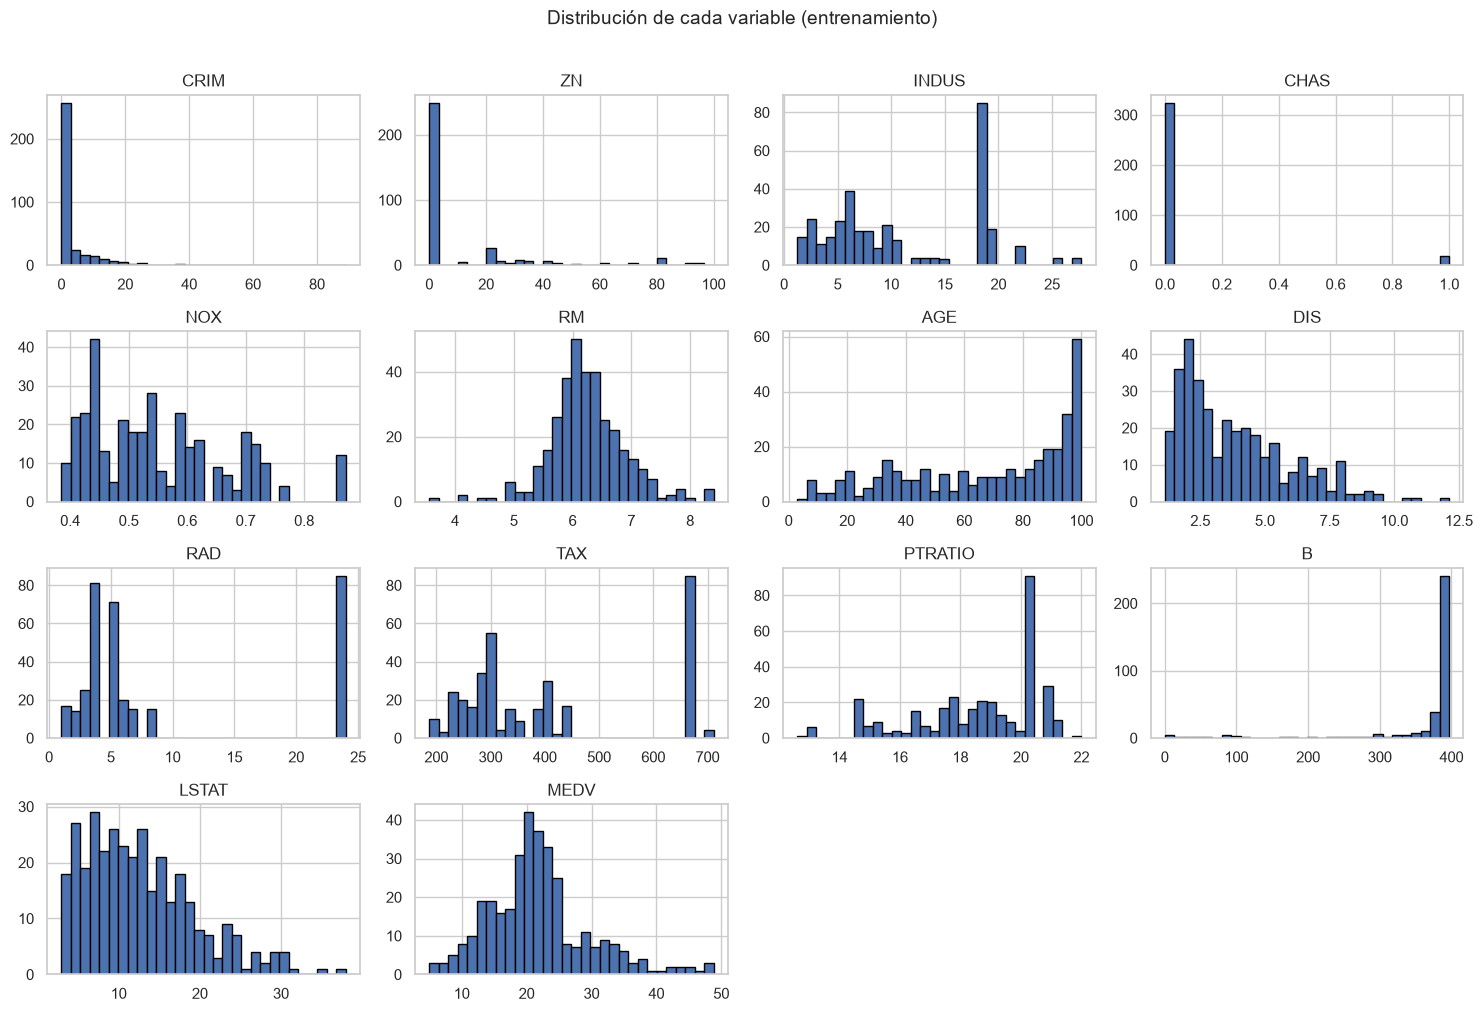

In [22]:
# Histogramas de todas las variables para ver la forma de cada distribución
train.hist(bins=30, figsize=(15, 10), edgecolor="black")
plt.suptitle("Distribución de cada variable (entrenamiento)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

*Figura 1. Histogramas de las 14 variables en el conjunto de entrenamiento.*

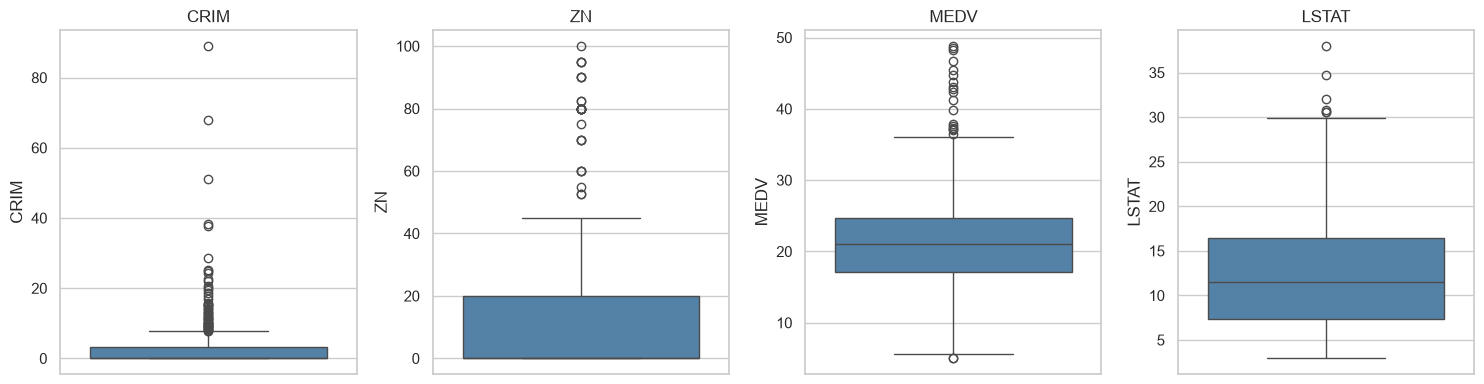

In [23]:
# Boxplots de las más asimétricas, para ver el tamaño de los valores atípicos
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["CRIM", "ZN", "MEDV", "LSTAT"]):
    sns.boxplot(y=train[col], ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

*Figura 2. Diagramas de caja de `CRIM`, `ZN`, `MEDV` y `LSTAT`, las variables más asimétricas, en entrenamiento.*

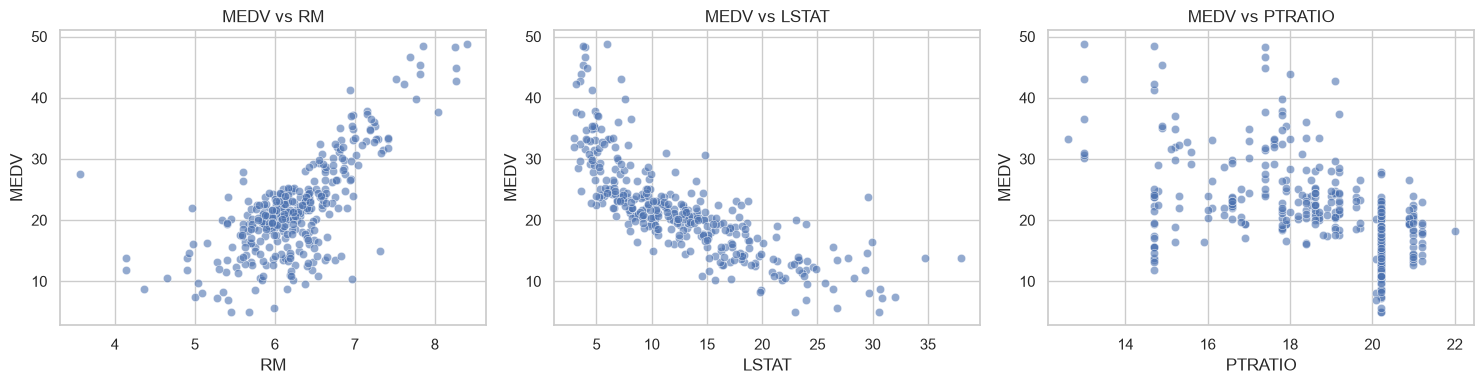

In [24]:
# MEDV contra las más correlacionadas, para ver si la relación da como una recta
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["RM", "LSTAT", "PTRATIO"]):
    sns.scatterplot(data=train, x=col, y="MEDV", ax=ax, alpha=0.6)
    ax.set_title(f"MEDV vs {col}")
plt.tight_layout()
plt.show()

*Figura 3. `MEDV` contra `RM`, `LSTAT` y `PTRATIO`, en entrenamiento.*

### Lectura de los gráficos

Los histogramas (Figura 1) confirman lo del sesgo: `CRIM` y `ZN` se amontonan cerca de cero con colas
largas, y `CHAS` es casi toda ceros. `MEDV` decrece de corrido, sin amontonarse en ningún
valor puntual.

En los diagramas de caja (Figura 2) hay un montón de puntos fuera de los bigotes, sobre todo en `CRIM`.
Decidimos no eliminarlos, a diferencia de las topeadas que sí sacamos. Un valor alto de criminalidad es un dato real: ese barrio tiene esa tasa, y es
justo el tipo de barrio que el modelo tiene que poder predecir. Un `MEDV` de 50, en cambio,
es un dato que no conocemos. Sacamos los segundos porque no son información y dejamos los
primeros porque sí lo son. Recortar los atípicos reales nos mejoraría las métricas de
mentira, entrenando y evaluando sobre una versión más fácil del problema.

Los scatterplots (Figura 3) muestran las dos relaciones más aprovechables para un modelo lineal: `RM`
sube con `MEDV` (más habitaciones, más valor) y `LSTAT` baja (más población de menor estatus
socioeconómico, menos valor). La de `LSTAT` se ve bastante curva, así que si la dejamos así
vamos a tener error sistemático en los extremos.

## Matriz de correlación

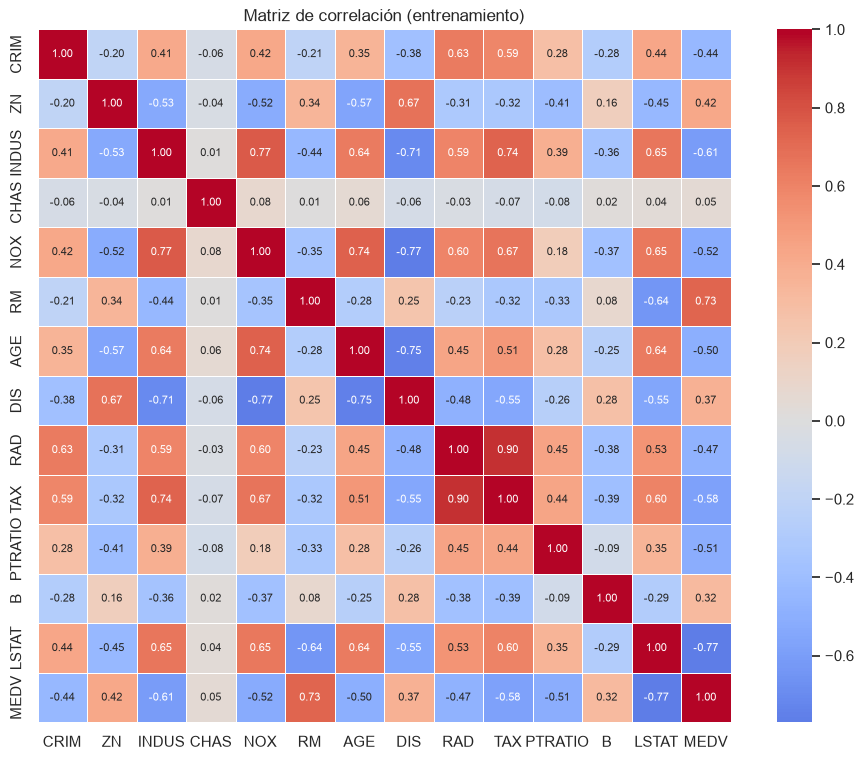

In [25]:
# Matriz de correlación de Pearson sobre el entrenamiento
correlacion = train.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, annot_kws={"size": 8})
plt.title("Matriz de correlación (entrenamiento)")
plt.show()

*Figura 4. Matriz de correlación de Pearson entre las 14 variables, calculada sobre entrenamiento.*

In [26]:
# Ordenamos la correlación de cada característica con la variable a predecir
correlacion["MEDV"].drop("MEDV").sort_values(key=abs, ascending=False).to_frame("correlación con MEDV").round(3)

,correlación con MEDV
LSTAT,-0.771
RM,0.729
INDUS,-0.610
TAX,-0.579
NOX,-0.525
PTRATIO,-0.509
AGE,-0.498
RAD,-0.475
CRIM,-0.444
ZN,0.425


In [27]:
# Buscamos pares muy correlacionados entre sí, que son los que dejan coeficientes inestables
import itertools

pares = [(a, b, correlacion.loc[a, b]) for a, b in itertools.combinations(X.columns, 2)
         if abs(correlacion.loc[a, b]) > 0.7]
pd.DataFrame(pares, columns=["variable A", "variable B", "correlación"]).round(3)

,variable A,variable B,correlación
0,INDUS,NOX,0.767
1,INDUS,DIS,-0.708
2,INDUS,TAX,0.735
3,NOX,AGE,0.738
4,NOX,DIS,-0.769
5,AGE,DIS,-0.751
6,RAD,TAX,0.904


### Lectura de la correlación

Las dos más fuertes con `MEDV` son `LSTAT` (−0,771) y `RM` (0,729). Después vienen `INDUS`
(−0,610), `TAX` (−0,579), `NOX` (−0,525) y `PTRATIO` (−0,509). Todas con el signo que uno
esperaría: más pobreza, más industria, más contaminación y más chicos por maestro tiran el
precio para abajo, y más habitaciones lo suben.

La excepción es `CHAS`, con 0,048: lindar con el río prácticamente no distingue el valor de
una vivienda. Queda como la variable menos informativa del conjunto. Igual la dejamos,
porque que no sirva sola no quiere decir que no aporte junto a las demás.

Entre las características hay bastante colinealidad (Figura 4). La peor es `RAD`–`TAX` (0,904): los
barrios con más acceso a autopistas son también los de más carga impositiva. El resto de los
pares fuertes son todos del mismo grupo de variables, que describen desde distintos ángulos
qué tan industrial y qué tan céntrico es un barrio: `INDUS` va con `NOX` (0,767) y con `TAX`
(0,735), `NOX` sube cuando baja `DIS` (−0,769) y sube con `AGE` (0,738), y `AGE` baja con
`DIS` (−0,751). Más industria va con más contaminación, y las zonas industriales son las
viejas y cercanas a los centros de empleo.

Dejamos las dos variables de cada par. La colinealidad no impide ajustar el modelo, pero
vuelve inestables los coeficientes, y sacar una a mano sería decidir arbitrariamente cuál de
las dos importa.

## Test de colinealidad: el VIF

La matriz de correlación mira las variables de a pares, y eso deja un agujero: una variable
puede no tener ninguna correlación alta con ninguna otra por separado y aun así ser casi una
combinación lineal de varias juntas. Con la correlación no lo veríamos.

El VIF tapa ese agujero. Para cada característica se hace una regresión lineal que la
predice usando **todas las demás**, se saca su $R^2_j$ y se calcula:

$$VIF_j = \frac{1}{1 - R^2_j}$$

Si una variable no se puede predecir a partir de las otras, su $R^2_j$ da
cerca de 0 y el VIF cerca de 1. Si se puede predecir casi perfecto, $R^2_j$ tiende a 1 y el
VIF se dispara. El nombre viene de lo que mide: cuántas veces se infla la varianza del
coeficiente estimado por culpa de la colinealidad. Un VIF de 9 quiere decir que el error
estándar de ese coeficiente es $\sqrt{9} = 3$ veces más grande que si la variable fuera
independiente del resto, o sea un coeficiente tres veces más inestable.

Tomamos VIF > 10 como colinealidad severa y VIF > 5 como moderada. Con la fórmula se ve qué
significan: un VIF de 10 quiere decir que el 90% de la variable se explica con las demás y que
el error estándar de su coeficiente se multiplica por más de 3 ($\sqrt{10} \approx 3,2$); uno
de 5, que se explica el 80% y que el error estándar se multiplica por más de 2
($\sqrt{5} \approx 2,2$).

In [28]:
# El VIF se calcula con regresiones lineales, así que lo importamos acá
from sklearn.linear_model import LinearRegression

In [29]:
def calcular_vif(datos):
    """Regresa cada variable contra todas las demás y devuelve su VIF = 1 / (1 - R²)."""
    filas = []
    for col in datos.columns:
        resto = datos.drop(columns=col)
        r2 = LinearRegression().fit(resto, datos[col]).score(resto, datos[col])
        filas.append({"variable": col, "R²": r2, "VIF": 1 / (1 - r2)})
    return pd.DataFrame(filas).set_index("variable").sort_values("VIF", ascending=False)

In [30]:
# VIF de las 13 características sobre el conjunto de entrenamiento
vif = calcular_vif(X_train)
vif.round(2)

,R²,VIF
variable,,
TAX,0.89,8.86
RAD,0.86,7.09
NOX,0.78,4.62
INDUS,0.76,4.19
DIS,0.75,4.00
LSTAT,0.70,3.36
AGE,0.69,3.18
ZN,0.57,2.32
RM,0.52,2.08


In [31]:
# Vemos cuáles pasan los umbrales que usamos de referencia
print(f"Colinealidad severa (VIF > 10):  {list(vif.index[vif['VIF'] > 10]) or 'ninguna'}")
print(f"Colinealidad moderada (VIF > 5): {list(vif.index[(vif['VIF'] > 5) & (vif['VIF'] <= 10)]) or 'ninguna'}")

Colinealidad severa (VIF > 10):  ninguna
Colinealidad moderada (VIF > 5): ['TAX', 'RAD']


### Lectura del VIF

Ninguna variable llega a colinealidad severa. Las dos más altas son `TAX` (8,86) y `RAD`
(7,09), que quedan en moderada, y el resto está por debajo de 5. Son justo las dos del par
más correlacionado de la matriz (0,90 en la Figura 4), así que el VIF confirma lo que veíamos pero con más
precisión: esa correlación de 0,90 impresiona, y lo que significa en términos de
inestabilidad es que el error estándar del coeficiente es unas tres veces el normal. Es un
problema, pero no es una catástrofe.

El VIF además corrige la lectura por pares. `INDUS` aparecía en tres
de los siete pares fuertes de la matriz (con `NOX`, `TAX` y `DIS`) y podía parecer la más
comprometida de todas; su VIF da 4,19, por debajo del umbral moderado. Que una variable se
correlacione con varias no significa que sea redundante: puede compartir un pedazo con cada
una y seguir teniendo información propia. El VIF, que las mira a todas juntas, es el que
responde esa pregunta.

Para el modelo, esto deja dos expectativas:

1. Los coeficientes de `RAD` y `TAX` no van a ser confiables. Con VIF de 7 y 9, el modelo
   puede repartir peso entre las dos de varias formas casi equivalentes, y cuál elige depende
   de la muestra.
2. Acota lo que podemos esperar de Ridge. Ridge sirve cuando la colinealidad infla la
   varianza de los coeficientes, y acá la infla en serio, así que vale la pena probarlo.
   Pero como ninguna está en zona severa, no esperamos una mejora grande en predicción: lo
   que debería mejorar sobre todo es la estabilidad de los coeficientes.

## Relaciones entre pares de variables

La matriz de correlación resume cada relación en un número, y ese número sólo mide
asociación **lineal**. Dos variables pueden tener una relación fuerte pero curva y dar una
correlación mediocre. Como lo que vamos a ajustar es un modelo lineal, necesitamos ver las
formas y no sólo los coeficientes.

Graficamos el pairplot de las 14 variables sobre entrenamiento (Figura 5). Le pasamos `corner=True`
para quedarnos con el triángulo inferior nomás, porque el superior tiene los mismos gráficos
con los ejes dados vuelta. La fila que más nos interesa es la última, `MEDV` contra cada
característica: ahí se ve si la relación que el modelo va a suponer recta lo es en serio.

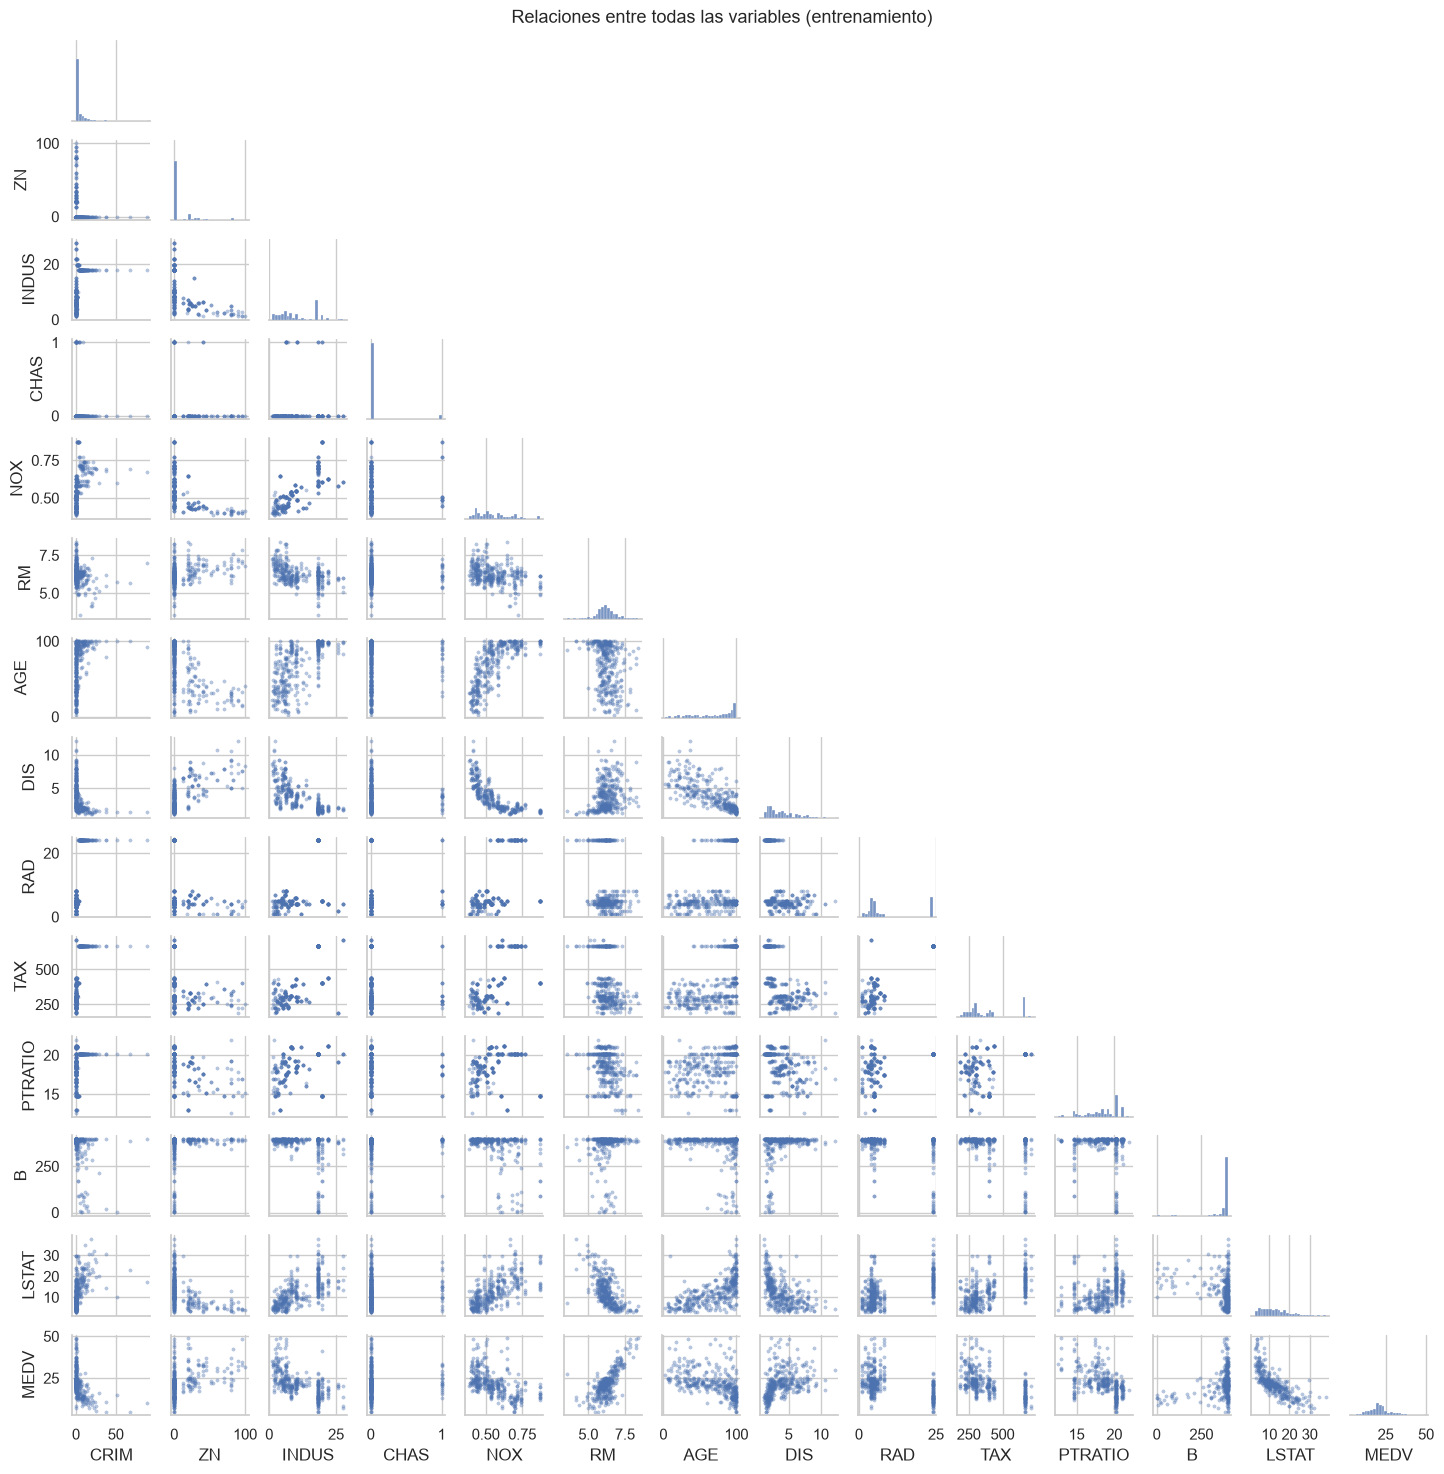

In [32]:
# Pairplot de todo sobre entrenamiento: lo que buscamos son relaciones curvas
g = sns.pairplot(train, corner=True, height=1.05,
                 plot_kws={"s": 6, "alpha": 0.4, "edgecolor": None},
                 diag_kws={"bins": 25})
g.figure.suptitle("Relaciones entre todas las variables (entrenamiento)", y=1.005, fontsize=13)
plt.show()

*Figura 5. Pairplot de las 14 variables en entrenamiento: la dispersión de cada par debajo de la diagonal y el histograma de cada variable en la diagonal.*

### Lectura del pairplot

En la última fila de la Figura 5, `MEDV` contra cada característica, se ven tres situaciones distintas:

- `LSTAT` tiene una relación claramente curva. Los puntos bajan rápido al principio y
  después se aplanan: es una curva convexa decreciente, no una recta. Pasar de 5% a 10% de
  población de menor estatus socioeconómico hace caer el precio mucho más que pasar de 25% a
  30%. Es el caso típico para aplicar logaritmo, y encima es la variable más correlacionada
  con `MEDV`, así que enderezarla es lo que más nos puede mejorar el ajuste.
- `RM` es la más parecida a una recta, con la nube bien repartida a lo largo de la diagonal.
  No necesita nada.
- `CRIM`, `ZN` y `CHAS` están aplastadas contra un borde. Casi todos los puntos amontonados
  en un extremo y unos pocos estirados lejos. En estas tres el problema no es la curvatura
  sino la escala: la nube ni llega a mostrar una forma.

En las diagonales se confirma lo del sesgo: `CRIM` es la más extrema, `ZN` y `CHAS` se
concentran en cero y las demás son más razonables. También se ven dos variables que se
parten en dos grupos en vez de repartirse continuo, `RAD` y `TAX`: hay un bloque de barrios
con accesibilidad e impuestos muy altos, separado del resto. Es la misma estructura que
produce la correlación de 0,90 entre ellas.

## Transformación logarítmica

El pairplot (Figura 5) nos mostró que al menos una relación no es recta, y un modelo lineal no puede
capturar eso. Se puede arreglar de dos formas: complicando el modelo, o enderezando la
variable. Vamos por la segunda, porque nos deja mantener el modelo lineal, que es lo que
pide el trabajo.

El logaritmo comprime la cola larga de una distribución asimétrica: separa los valores
chicos, que estaban amontonados, y junta los grandes, que estaban desparramados. Cuando la
relación con la variable a predecir es del tipo "al principio el efecto es fuerte y después
se agota", eso es justo lo que la convierte en una recta.

Para elegir qué transformar nos pusimos tres condiciones, y tienen que darse las tres:

1. La variable tiene que ser estrictamente positiva (el logaritmo no existe en 0 ni en
   negativos).
2. Tiene que tener sesgo positivo apreciable.
3. El logaritmo tiene que fortalecer su relación lineal con `MEDV`, que es lo único que le
   importa al modelo. Que una variable sea asimétrica no es un problema en sí: las
   distribuciones asimétricas no violan ningún supuesto de la regresión lineal. El problema
   es la relación curva.

La decisión la tomamos mirando sólo entrenamiento. Después aplicar el logaritmo a los tres
conjuntos no es filtración: a diferencia del escalado, transforma cada valor por separado
con una función fija y no estima ningún parámetro a partir de los datos.

In [33]:
# Candidatas: las estrictamente positivas y con sesgo positivo apreciable
candidatas = [c for c in X_train.columns if X_train[c].min() > 0 and X_train[c].skew() > 0.5]
print(f"Candidatas a transformar: {candidatas}")

Candidatas a transformar: ['CRIM', 'NOX', 'DIS', 'RAD', 'TAX', 'LSTAT']


In [34]:
# Para cada una: cuánto le corrige el sesgo el log y cuánto le mejora la relación con MEDV
comparacion = pd.DataFrame({
    "sesgo": X_train[candidatas].skew(),
    "sesgo con log": np.log(X_train[candidatas]).skew(),
    "r con MEDV": [X_train[c].corr(y_train) for c in candidatas],
    "r con log": [np.log(X_train[c]).corr(y_train) for c in candidatas],
}).round(3)
comparacion["mejora |r|"] = (comparacion["r con log"].abs() - comparacion["r con MEDV"].abs()).round(3)
comparacion.sort_values("mejora |r|", ascending=False)

,sesgo,sesgo con log,r con MEDV,r con log,mejora |r|
CRIM,5.394,0.467,-0.444,-0.577,0.133
DIS,0.989,0.112,0.366,0.439,0.073
LSTAT,0.896,-0.236,-0.771,-0.830,0.059
NOX,0.815,0.443,-0.525,-0.534,0.009
TAX,0.731,0.389,-0.579,-0.582,0.003
RAD,1.076,0.264,-0.475,-0.421,-0.054


### Qué transformamos y qué no

La tabla nos separó las candidatas en tres grupos:

- `NOX`, `TAX` y `RAD`: el logaritmo les corrige el sesgo pero la relación con `MEDV` no
  mejora, y en `RAD` incluso empeora (de 0,475 a 0,421). Quedan afuera: corregir el sesgo
  por sí solo no le sirve de nada al modelo.
- `LSTAT`: el sesgo pasa de 0,90 a −0,24 y la correlación con `MEDV` sube de −0,771 a
  −0,830. Es la mejora más grande y coincide con la curvatura que veíamos en el pairplot (Figura 5).
  La transformamos.
- `CRIM` y `DIS`: los números invitan a transformarlas (`CRIM` mejora su correlación de
  −0,444 a −0,577), pero una correlación más alta con `MEDV` puede ser señal que otras
  variables ya estaban aportando.

In [35]:
# ¿Y si también transformamos CRIM? Comparamos el VIF en los dos casos
X_log_lstat = X_train.copy()
X_log_lstat["LSTAT"] = np.log(X_log_lstat["LSTAT"])

X_log_ambas = X_log_lstat.copy()
X_log_ambas["CRIM"] = np.log(X_log_ambas["CRIM"])

pd.DataFrame({"sin log": calcular_vif(X_train)["VIF"],
              "log LSTAT": calcular_vif(X_log_lstat)["VIF"],
              "log LSTAT y CRIM": calcular_vif(X_log_ambas)["VIF"]}
             ).sort_values("log LSTAT y CRIM", ascending=False).round(2)

,sin log,log LSTAT,log LSTAT y CRIM
variable,,,
RAD,7.09,7.08,9.60
TAX,8.86,8.88,8.90
CRIM,1.76,1.74,8.11
NOX,4.62,4.60,4.94
INDUS,4.19,4.20,4.22
LSTAT,3.36,4.10,4.13
DIS,4.00,4.03,3.97
AGE,3.18,3.39,3.44
ZN,2.32,2.34,2.40


Esto nos sacó la duda. Transformar `LSTAT` no le mueve el VIF a nadie: el suyo sube de 3,36
a 4,10, sigue por debajo del umbral, y el resto queda igual. Transformar `CRIM`, en cambio,
le dispara el VIF de 1,76 a 8,11 y de paso empuja a `RAD` de 7,09 a 9,60, al borde de la
colinealidad severa.

 Que `log(CRIM)` se
correlacione mejor con `MEDV` no quiere decir que aporte información nueva: un VIF de 8,11
dice que el 88% de `log(CRIM)` se puede predecir a partir de las otras doce variables. La
señal que gana en la correlación es señal que `RAD`, `TAX` y `NOX` ya estaban aportando. O
sea que lo que sumaría al modelo no es información, es inestabilidad, y no nos parece que
compense justo después de habernos armado un diagnóstico para medirla.

Con `DIS` el caso es distinto: no empeora la colinealidad, pero la mejora en la correlación
es la mitad que la de `LSTAT` y su relación con `MEDV` en el pairplot (Figura 5) no se ve curva, así
que no hay curvatura que corregir.

Así que transformamos solamente `LSTAT`.

In [36]:
# Aplicamos el log a las que elegimos, en los tres conjuntos igual
VARIABLES_LOG = ["LSTAT"]

X_train_log, X_val_log, X_test_log = X_train.copy(), X_val.copy(), X_test.copy()
for col in VARIABLES_LOG:
    for conjunto in (X_train_log, X_val_log, X_test_log):
        conjunto[col] = np.log(conjunto[col])

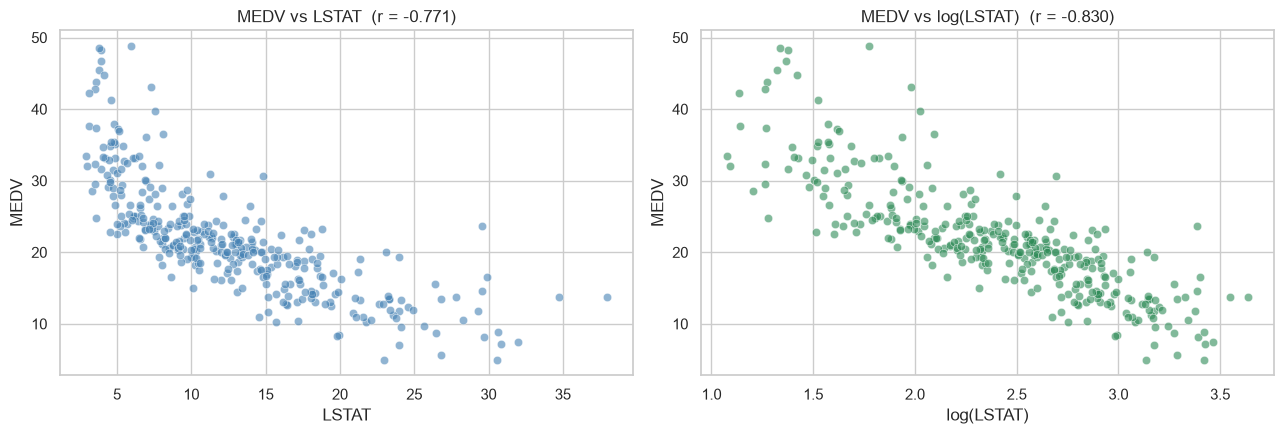

In [37]:
# Chequeamos que haya funcionado: la relación con MEDV tendría que quedar más recta
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x=X_train["LSTAT"], y=y_train, ax=axes[0], alpha=0.6, color="steelblue")
axes[0].set_title(f"MEDV vs LSTAT  (r = {X_train['LSTAT'].corr(y_train):.3f})")
sns.scatterplot(x=X_train_log["LSTAT"], y=y_train, ax=axes[1], alpha=0.6, color="seagreen")
axes[1].set_xlabel("log(LSTAT)")
axes[1].set_title(f"MEDV vs log(LSTAT)  (r = {X_train_log['LSTAT'].corr(y_train):.3f})")
plt.tight_layout()
plt.show()

*Figura 6. `MEDV` contra `LSTAT` (izquierda) y contra log(`LSTAT`) (derecha), en entrenamiento, con la correlación de cada caso en el título.*

Quedó como esperábamos. En el panel izquierdo de la Figura 6 los puntos bajan rápido y después se
aplanan, que es la curva que no puede seguir una recta. En el derecho la nube ya se
acomoda alrededor de una recta, sin esa panza, y la correlación sube de −0,771 a −0,830.
Con esto la variable más importante del modelo entra en una forma que la regresión lineal
puede aprovechar.

## Codificación de variables categóricas

Acá no hay nada que codificar:

- Las catorce columnas vinieron numéricas y ese tipo es el correcto en todos los casos. No
  hay ninguna columna de texto ni ninguna categoría nominal.
- `CHAS` es la única categórica del conjunto, pero es binaria y ya viene como 0/1, que es
  justo lo que daría aplicarle codificación *dummy*.
- `RAD` es la única que nos hizo dudar, porque toma nueve valores distintos y podría pasar
  por categórica. Pero es un índice **ordinal**: más alto significa más accesibilidad a las
  autopistas. Dejarla como numérica conserva ese orden, que es información útil. Con
  *one-hot* quedarían nueve columnas sin relación entre sí, perdiendo el orden y sumando
  dimensiones sin ganar nada.

## Escalado de los datos

Estandarizamos: a cada variable le restamos su media y la dividimos por su desvío, para que
todas queden en una escala comparable. Es indispensable para el gradiente descendente (con
escalas dispares converge lento y mal) y para la regularización, donde la penalización
compara los coeficientes entre sí y sin escalar castigaría más a unas variables que a otras
sólo por la unidad en la que están medidas. A `CHAS` también la escalamos: al ser binaria el
cambio es cosmético, pero así no tenemos que tratar esa columna aparte.

Escalamos las variables ya transformadas, o sea con `LSTAT` en logaritmo. El orden importa:
estandarizar y después tomar logaritmo no daría lo mismo (habría valores negativos), y
además lo que queremos centrar y reescalar es la variable tal como va a entrar al modelo.

El escalador aprende dos parámetros de los datos, la media y el desvío de cada variable, así
que lo ajustamos sólo con entrenamiento y después lo aplicamos, tal como quedó, a validación
y prueba.

In [38]:
# El escalador, configurado para que devuelva DataFrame y no array
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler().set_output(transform="pandas")

In [39]:
# Lo ajustamos con entrenamiento y a los otros dos sólo les aplicamos lo ya ajustado
X_train_prep = escalador.fit_transform(X_train_log)
X_val_prep = escalador.transform(X_val_log)
X_test_prep = escalador.transform(X_test_log)

In [40]:
# Chequeamos el escalado: entrenamiento tiene que dar media 0 y desvío 1, los otros dos no
pd.DataFrame({"media train": X_train_prep.mean(), "desvío train": X_train_prep.std(),
              "media val": X_val_prep.mean(), "desvío val": X_val_prep.std(),
              "media test": X_test_prep.mean(), "desvío test": X_test_prep.std()}).round(3)

,media train,desvío train,media val,desvío val,media test,desvío test
CRIM,0.0,1.001,0.062,1.274,0.026,0.917
ZN,-0.0,1.001,-0.136,0.863,-0.003,1.060
INDUS,-0.0,1.001,0.081,1.010,0.036,1.055
CHAS,-0.0,1.001,-0.064,0.874,0.115,1.203
NOX,0.0,1.001,0.146,0.998,0.087,0.965
RM,-0.0,1.001,0.098,1.070,-0.030,1.062
AGE,-0.0,1.001,0.074,1.005,0.103,0.919
DIS,-0.0,1.001,-0.023,0.871,-0.026,1.099
RAD,-0.0,1.001,0.146,1.063,0.062,1.039
TAX,-0.0,1.001,0.185,1.037,0.042,1.015


La tabla confirma que no hubo filtración. Entrenamiento queda con
media exactamente 0 y desvío 1, porque es el que se usó para calcular esos parámetros. (La
tabla muestra 1,001 y no 1 por una diferencia de convención: `StandardScaler` divide por el
desvío poblacional y `pandas` informa el muestral.) Validación y prueba no dan 0 y 1: sus
valores se transformaron con la media y el desvío de entrenamiento, sin que sus propios
datos entraran en el cálculo. Si esta tabla diera 0 y 1 exactos en las tres columnas, sería
señal de que escalamos todo junto y de que las métricas están contaminadas.

Cuánto se apartan de 0 y 1 depende de la variable, y en algunas la diferencia es grande. Son
las más asimétricas y la binaria, que dependen de unos pocos valores extremos o de una
proporción baja de unos. En un conjunto de 49 filas, que caigan unos pocos casos atípicos de
más o de menos mueve mucho el desvío. No es un problema del escalado, es un recordatorio de
que validación es chica y de que sus métricas hay que leerlas con margen: sirven para
ordenar configuraciones, no para estimar con precisión el error del modelo.

# Regresión lineal múltiple

La regresión lineal múltiple supone que `MEDV` se
puede escribir como una combinación lineal de las 13 características:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_{13} x_{13}$$

donde $w_0$ es la ordenada al origen y cada $w_j$ es el peso de una característica. Entre
los métodos de este ítem lo que cambia no es la forma del modelo sino cómo se buscan esos
pesos: mínimos cuadrados los resuelve de una con una fórmula, el gradiente descendente los
va corrigiendo de a poco, y la regularización le agrega a esa búsqueda una penalización al
tamaño de los pesos.

## Las métricas que vamos a usar

Entre R², MSE, RMSE, MAE y MAPE nos quedamos con tres, porque cada
una contesta algo distinto y juntas se complementan:

- **R²**: qué proporción de la variabilidad de `MEDV` explica el modelo. No tiene unidades,
  así que sirve para comparar entre conjuntos de distinto tamaño y contra un modelo trivial:
  R² = 0 es predecir siempre el promedio y R² = 1 es acertar exacto. Es la que usamos de
  referencia para comparar modelos.
- **RMSE**: queda en las mismas unidades que `MEDV` (miles de dólares), así que se lee
  directo como "el modelo se equivoca en promedio en tantos miles". Además es la raíz de la
  función que mínimos cuadrados y el gradiente descendente minimizan, o sea que mide justo
  lo que el modelo está tratando de optimizar. Como eleva los errores al cuadrado, castiga
  fuerte los desvíos grandes.
- **MAE**: también en miles de dólares, pero promedia los errores sin elevarlos al cuadrado,
  así que no se le infla por unos pocos casos muy errados. Mirarlo junto al RMSE es
  informativo: si el RMSE es bastante más grande que el MAE, quiere decir que el error no
  está repartido parejo sino concentrado en unas pocas observaciones mal predichas.

Las otras dos las descartamos. El MSE tiene la misma información que el RMSE pero en "miles
de dólares al cuadrado", una unidad que no se puede interpretar; el RMSE es el mismo número
ya devuelto a una escala legible. El MAPE mide el error como porcentaje del valor real, y
acá eso distorsiona: `MEDV` va de 5 a 50, así que errar por 2 en una vivienda de 5 pesaría
diez veces más que el mismo error en una de 50, cuando para el problema los dos errores
valen igual.

### Por qué medimos sobre entrenamiento y sobre prueba

Mirar uno solo de los dos no alcanza:

- Sólo entrenamiento mide qué tan bien el modelo reproduce los datos que ya vio, y eso no
  dice nada sobre datos nuevos: un modelo con suficiente flexibilidad puede memorizar el
  entrenamiento y después fallar por completo afuera.
- Sólo prueba dice si el modelo sirve, pero no por qué cuando no sirve, y el diagnóstico
  cambia por completo qué habría que hacer.

Lo que informa es la diferencia entre las dos. Si el modelo anda bien en entrenamiento y mal
en prueba, está sobreajustado: aprendió el ruido de esas filas y hay que simplificarlo o
regularizarlo. Si anda mal en los dos, está subajustado: es demasiado rígido para la
relación que hay en los datos, y regularizar lo empeoraría todavía más. Sin la métrica de
entrenamiento no podemos distinguir un caso del otro.

In [41]:
# El modelo de mínimos cuadrados y las tres métricas que elegimos
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [42]:
def metricas(y_real, y_pred):
    """Devuelve las tres métricas elegidas para un conjunto dado."""
    return pd.Series({"R²": r2_score(y_real, y_pred),
                      "RMSE": root_mean_squared_error(y_real, y_pred),
                      "MAE": mean_absolute_error(y_real, y_pred)})

In [43]:
def evaluar(pred_train, pred_val, pred_test):
    """Arma la tabla de métricas de un modelo sobre los tres conjuntos."""
    return pd.DataFrame({"entrenamiento": metricas(y_train, pred_train),
                         "validación": metricas(y_val, pred_val),
                         "prueba": metricas(y_test, pred_test)}).round(3)

In [44]:
def tabla_comparativa(predicciones):
    """Igual que evaluar pero para varios modelos: recibe {modelo: {conjunto: predicción}}."""
    reales = {"entrenamiento": y_train, "validación": y_val, "prueba": y_test}
    filas = {(modelo, conjunto): metricas(reales[conjunto], pred)
             for modelo, preds in predicciones.items()
             for conjunto, pred in preds.items()}
    return pd.DataFrame(filas).T.round(4)

In [45]:
# Acá vamos guardando las métricas de prueba de cada modelo, para compararlos al final
resultados = {}

## `LinearRegression`: mínimos cuadrados

`LinearRegression` busca los pesos que minimizan la suma de los errores al cuadrado sobre
entrenamiento. No los busca probando: ese problema tiene solución exacta, que sale de
resolver un sistema de ecuaciones, así que el modelo llega al óptimo de una, sin iteraciones
y sin hiperparámetros que elegir. Por eso lo usamos de punto de partida: da el mejor ajuste
lineal posible sobre entrenamiento, y todo lo demás se compara contra él.

Lo entrenamos con los datos escalados. A mínimos cuadrados el escalado no le hace falta (la
solución exacta no depende de la escala), pero lo usamos igual por dos motivos: los
coeficientes quedan todos en la misma unidad y se pueden comparar entre sí, y todos los
modelos del trabajo quedan entrenados exactamente sobre los mismos datos, que es condición
para que la comparación del ítem 6 sea justa.

In [46]:
# Entrenamos el modelo con los datos escalados
lineal = LinearRegression()
lineal.fit(X_train_prep, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-1.27, 0.4 ,-0.15,...,-1.52, 0.83,-3.71]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,21.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [47]:
# Chequeamos que a mínimos cuadrados el escalado no le cambia las predicciones
sin_escalar = LinearRegression().fit(X_train_log, y_train)
print(f"R² de prueba con datos escalados:   {r2_score(y_test, lineal.predict(X_test_prep)):.6f}")
print(f"R² de prueba sin escalar:           {r2_score(y_test, sin_escalar.predict(X_test_log)):.6f}")

R² de prueba con datos escalados:   0.769052
R² de prueba sin escalar:           0.769052


In [48]:
# La ordenada al origen, comparada con el precio promedio
print(f"Ordenada al origen (w0): {lineal.intercept_:.3f}")
print(f"Precio medio en entrenamiento: {y_train.mean():.3f}")

Ordenada al origen (w0): 21.802
Precio medio en entrenamiento: 21.802


In [49]:
# Los coeficientes ordenados por tamaño, para ver cuánto pesa cada variable
coeficientes = pd.Series(lineal.coef_, index=X_train_prep.columns)
coeficientes.sort_values(key=abs, ascending=False).to_frame("coeficiente").round(3)

,coeficiente
LSTAT,-3.715
DIS,-2.321
RM,2.147
RAD,2.104
TAX,-1.980
PTRATIO,-1.523
CRIM,-1.265
NOX,-0.980
B,0.826
ZN,0.398


### Lectura de los coeficientes

La ordenada al origen da 21,80, que es justo el precio medio del entrenamiento. Tiene
sentido: como las características están centradas en 0, un barrio que sea promedio en las
trece tiene todos los términos $w_j x_j$ en cero, así que el modelo le predice $w_0$. Con
datos estandarizados el intercepto es la predicción para el barrio promedio.

Como todas las variables están en desvíos estándar, los coeficientes se leen igual entre sí:
cuánto cambia el precio predicho, en miles de dólares, si esa variable sube un desvío y las
demás quedan fijas. `LSTAT` es la más influyente por lejos (−3,72), ahora en su versión
logarítmica. Después vienen `DIS` (−2,32), `RM` (2,15), `RAD` (2,10) y `TAX` (−1,98).

Hay algo que no cierra con la matriz de correlación. Por sí sola,
`DIS` se correlaciona positivamente con `MEDV` (0,366), pero su coeficiente en el modelo da
negativo. Con `RAD` pasa al revés: correlación −0,475 y coeficiente +2,10. Las dos cambian
de signo al pasar de la correlación al modelo.

No es un error, es justo lo que nos había anticipado el VIF. La correlación mira la variable
sola, mientras que el coeficiente mide lo que aporta dado que las demás ya están en el
modelo. `DIS` venía muy correlacionada con `NOX` (−0,769) y con `AGE` (−0,751); una vez que
esas dos explican la parte de "barrio viejo y contaminado", lo que `DIS` agrega por encima
cambia de signo. Lo mismo con `RAD`–`TAX` (0,904), el par más colineal y el de los VIF más
altos (7,09 y 8,86): con `TAX` adentro, el aporte propio de `RAD` se da vuelta.

Estos coeficientes no son confiables uno por uno. Un VIF de
8,86 en `TAX` significa que el error estándar de su coeficiente es casi tres veces el que
tendría sin colinealidad, así que otra muestra repartiría el peso entre `RAD` y `TAX` de
otra forma. Sirven para predecir, no para salir a afirmar que tener autopistas cerca
encarece las viviendas. Es el escenario donde Ridge debería ayudar.

In [50]:
# Predecimos en los tres conjuntos
pred_train = lineal.predict(X_train_prep)
pred_val = lineal.predict(X_val_prep)
pred_test = lineal.predict(X_test_prep)

In [51]:
# Métricas en los tres conjuntos, y las guardamos para la comparación del final
tabla_lineal = evaluar(pred_train, pred_val, pred_test)
resultados["LinearRegression"] = metricas(y_test, pred_test)
tabla_lineal

,entrenamiento,validación,prueba
R²,0.831,0.663,0.769
RMSE,3.225,4.322,3.878
MAE,2.453,3.025,2.850


### Lectura de las métricas

El modelo explica el 77% de la variabilidad del precio en prueba (R² = 0,769) y se equivoca
en promedio unos 3.900 dólares (RMSE = 3,878), sobre un precio mediano de 20.900. O sea, un
error del orden del 19% del valor típico de una vivienda. No es un modelo preciso, pero
captura buena parte de la señal.

Comparando entre conjuntos, no hay sobreajuste serio. El R² baja de 0,831 en entrenamiento a
0,769 en prueba: hay una caída pero es moderada y era esperable. Con 13 características y
343 filas, un modelo lineal no tiene flexibilidad como para memorizar el entrenamiento
aunque quisiera. Si este modelo tiene algún problema, va para el otro lado.

El R² de validación (0,663) queda bastante por debajo del de prueba, lo que a primera vista
descoloca. No hay que leer mucho en eso: validación tiene 49 filas, y con tan pocas
observaciones la métrica se mueve varios puntos según qué barrios hayan caído ahí. Sirve para ordenar configuraciones, no para estimar el error final.

Lo más informativo es la relación entre RMSE (3,878) y MAE (2,850). Si los errores
estuvieran repartidos parejo los dos números serían parecidos; que el RMSE sea un 36% más
grande dice que el error está concentrado en unas pocas observaciones bastante mal
predichas. La Figura 7 muestra dónde están.

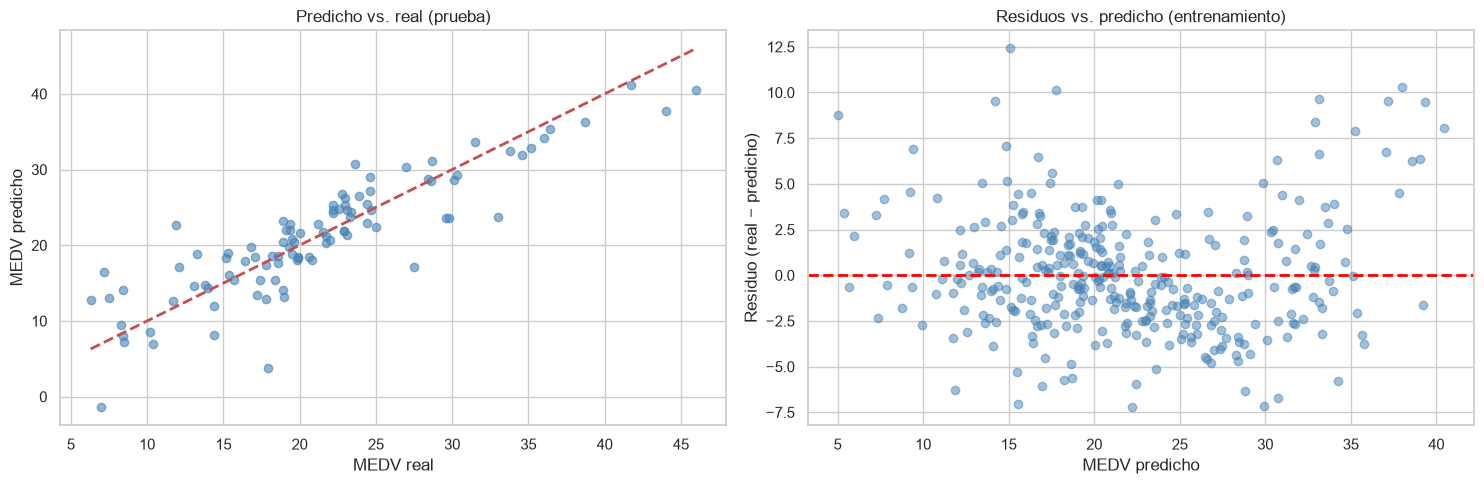

In [52]:
# Dos gráficos para ver cómo ajusta: qué tan cerca cae y cómo se reparte el error
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test, pred_test, alpha=0.6, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_xlabel("MEDV real")
axes[0].set_ylabel("MEDV predicho")
axes[0].set_title("Predicho vs. real (prueba)")

residuos = y_train - pred_train
axes[1].scatter(pred_train, residuos, alpha=0.5, color="steelblue")
axes[1].axhline(0, color="red", ls="--", lw=2)
axes[1].set_xlabel("MEDV predicho")
axes[1].set_ylabel("Residuo (real − predicho)")
axes[1].set_title("Residuos vs. predicho (entrenamiento)")

plt.tight_layout()
plt.show()

*Figura 7. `LinearRegression`: valor predicho contra valor real en prueba (izquierda) y residuo contra valor predicho en entrenamiento (derecha). Las líneas discontinuas marcan la predicción perfecta y el residuo cero.*

In [53]:
# Residuo medio por tramo: si el modelo estuviera bien, tendría que dar cerca de 0 en todos
tramos = pd.cut(pred_train, [-10, 15, 20, 25, 30, 60])
pd.DataFrame({"residuo medio": residuos.groupby(tramos, observed=True).mean(),
              "viviendas": residuos.groupby(tramos, observed=True).size()}).round(2)

,residuo medio,viviendas
"(-10, 15]",0.66,56
"(15, 20]",0.31,94
"(20, 25]",-0.52,86
"(25, 30]",-1.97,53
"(30, 60]",1.52,54


In [54]:
# Nada le impide a una recta predecir precios negativos, así que lo chequeamos
print(f"Predicción mínima en entrenamiento: {pred_train.min():.2f}")
print(f"Predicción mínima en prueba:        {pred_test.min():.2f}")

Predicción mínima en entrenamiento: 5.03
Predicción mínima en prueba:        -1.41


### ¿Conseguimos un buen fitting?

Nos parece que sí, un ajuste razonable para un modelo lineal, pero con un techo que ya no se
puede correr sin salirse de la regresión lineal. La Figura 7 y las dos celdas que le siguen muestran dos problemas, y
ninguno se arregla cambiando el método de optimización.

La relación no es del todo lineal. En el panel de residuos de la Figura 7 la nube debería verse como
una banda sin forma alrededor del cero. En cambio los residuos medios por tramo dibujan una
U: son positivos en las viviendas baratas (+0,66 y +0,31), negativos en la franja de 20 a 30
(−0,52 y −1,97) y vuelven a ser positivos en las caras (+1,52). Que el signo del error
dependa del valor predicho significa que al modelo le falta curvatura: subestima en los
extremos y sobreestima en el medio. Enderezar `LSTAT` resolvió la curvatura más marcada,
pero no era la única variable con una relación que no es del todo recta.
Corregir lo que queda pediría términos polinómicos o interacciones, que se van del alcance
del ítem.

Queda una predicción negativa en prueba, de −1,41. Una recta no tiene forma de saber que un
precio no puede bajar de cero, y extrapola sin límite en los barrios más desfavorecidos. Es
una limitación estructural de la regresión lineal sobre una variable acotada por abajo, no
algo que se arregle con más datos.

Contestando la pregunta del enunciado: el problema de este modelo no es sobreajuste (la
caída de 0,831 a 0,769 es moderada) sino sesgo. Es un modelo rígido para la forma que tienen
estos datos.

El gradiente
descendente busca los mismos pesos por otro camino, así que en el mejor de los casos
debería llegar a métricas equivalentes, nunca mejores; si da algo distinto es que no terminó
de converger. Y la regularización sirve para bajar varianza, que no es nuestro problema, así
que tampoco esperamos una mejora grande en predicción: lo que debería cambiar
son los coeficientes inestables que marcó el VIF en `RAD` y `TAX`.

## Gradiente descendente

Mínimos cuadrados resuelve el problema de una, con una fórmula. El gradiente descendente
llega al mismo lugar pero iterando: arranca con pesos cualquiera y los va corrigiendo de a
poco, siempre en la dirección que más baja el error.

La función de costo que queremos minimizar es el MSE:

$$J(W) = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

y su gradiente respecto de los pesos es:

$$\nabla J(W) = -\frac{2}{n} X^T (y - XW)$$

El gradiente apunta hacia donde el error *crece*, así que para bajarlo hay que ir para el
otro lado. De ahí sale la regla de actualización:

$$W \leftarrow W - lr \cdot \nabla J(W)$$

donde $lr$ es el paso de aprendizaje, que decide cuánto nos movemos en cada corrección.

Si ya tenemos la solución exacta, ¿para qué queremos esto? Acá, con 13 variables y 343
filas, la verdad es que no hace falta. Pero el método sirve cuando el dataset es tan grande
que resolver el sistema de ecuaciones no entra en memoria, y sobre todo es la base de cómo
se entrena casi cualquier modelo más complejo, donde solución cerrada directamente no hay.

Probamos tres variantes, que se diferencian en cuántos datos usan para calcular cada
corrección:

- **Por lotes (batch)**: usa las 343 filas en cada paso. El gradiente es el exacto, pero
  cada paso cuesta.
- **Estocástico (SGD)**: usa una sola fila por paso. Cada corrección sale rapidísimo pero
  apunta para cualquier lado.
- **Mini-batch**: el punto medio, va de a grupos de 32 filas.

Acá el escalado que hicimos antes se vuelve imprescindible. Si las variables tuvieran
escalas muy distintas, un mismo `lr` sería enorme para unas y mínimo para otras, y en vez
de bajar derecho el descenso zigzaguearía.

Las tres variantes son las funciones `gradient_descent`, `stochastic_gradient_descent` y
`mini_batch_gradient_descent` del notebook `Implementaciones-Descenso-del-Gradiente.ipynb`,
que está en esta misma carpeta. Ese notebook, además de definirlas, carga dos datasets
propios que acá no existen, así que correrlo entero con `%run` falla. Por eso leemos el
archivo y ejecutamos sólo las tres celdas que definen las funciones.

A las funciones les cambiamos dos cosas, y ninguna toca el algoritmo. La versión original
devuelve sólo los pesos finales: el error de cada paso lo calcula para graficarlo y después
lo descarta. Ahora devuelve también esas dos listas, porque las necesitamos para comparar
las variantes entre sí y contra mínimos cuadrados. Además le agregamos un parámetro
`graficar`. Por defecto el gráfico sale igual que antes, y en los barridos de hiperparámetros
lo apagamos para no dibujar uno por cada configuración.

Las funciones arrancan de pesos al azar y no reciben semilla, así que antes de cada llamada
fijamos la de numpy. Si no, cada corrida daría un resultado distinto.

In [55]:
# Ejecutamos sólo las celdas del notebook de implementaciones que definen las tres funciones
import json

FUNCIONES_GRADIENTE = ("gradient_descent", "stochastic_gradient_descent", "mini_batch_gradient_descent")
with open("Implementaciones-Descenso-del-Gradiente.ipynb", encoding="utf-8") as archivo:
    celdas_implementaciones = json.load(archivo)["cells"]
for celda in celdas_implementaciones:
    fuente = "".join(celda["source"])
    if fuente.startswith(tuple(f"def {nombre}(" for nombre in FUNCIONES_GRADIENTE)):
        exec(fuente)

In [56]:
# Las tres quedaron definidas, con la firma que tienen en el otro notebook
import inspect

for funcion in (gradient_descent, stochastic_gradient_descent, mini_batch_gradient_descent):
    print(f"{funcion.__name__}{inspect.signature(funcion)}")

gradient_descent(X_train, y_train, X_val, y_val, lr=0.01, epochs=100, graficar=True)
stochastic_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100, graficar=True)
mini_batch_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100, batch_size=11, graficar=True)


In [57]:
# Las funciones trabajan con arrays de numpy, así que convertimos y dejamos y como columna
X_train_np = X_train_prep.values
X_val_np = X_val_prep.values
X_test_np = X_test_prep.values

y_train_np = y_train.values.reshape(-1, 1)
y_val_np = y_val.values.reshape(-1, 1)

In [58]:
def predecir(X, W):
    """Predice con los pesos que devuelven las funciones de gradiente, que traen el intercepto primero."""
    return (np.hstack((np.ones((X.shape[0], 1)), X)) @ W).ravel()

In [59]:
# El MSE que consiguió mínimos cuadrados: es el piso al que debería llegar el gradiente
mse_ols = np.mean((y_train - lineal.predict(X_train_prep)) ** 2)
print(f"MSE de entrenamiento de LinearRegression: {mse_ols:.4f}")

MSE de entrenamiento de LinearRegression: 10.4011


### Gradiente por lotes

Usamos `lr = 0.05` y 1000 épocas, valores de partida que todavía no salen de ningún barrido.

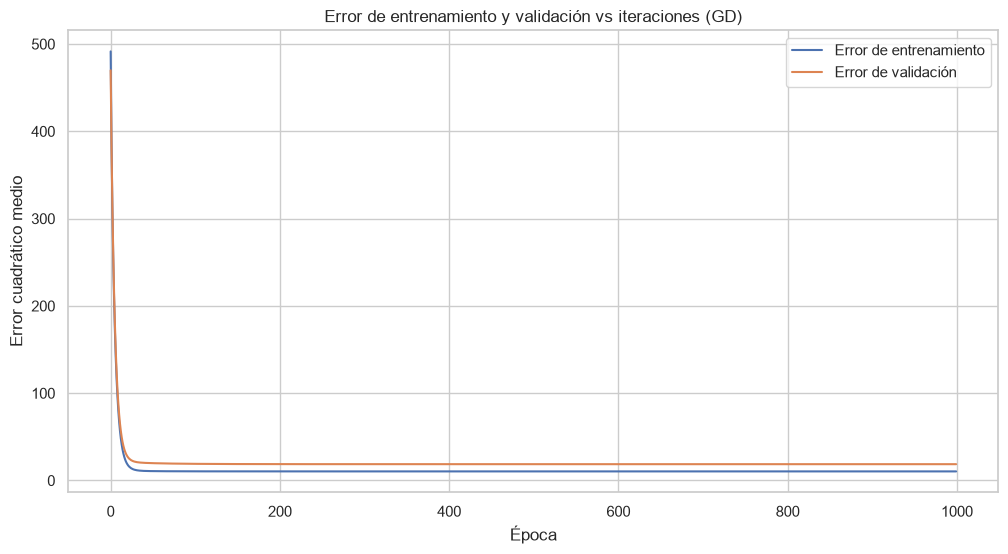

In [60]:
# Entrenamos con el gradiente por lotes y vemos cómo baja el error
np.random.seed(SEMILLA)
W_gd, err_train_gd, err_val_gd = gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.05, epochs=1000)

*Figura 8. Gráfico de `gradient_descent` con `lr = 0.05`: MSE de entrenamiento y de validación en cada paso, que en el gradiente por lotes es una época.*

In [61]:
# Comparamos los pesos que encontró con los de mínimos cuadrados
pesos = pd.DataFrame({"mínimos cuadrados": np.concatenate([[lineal.intercept_], lineal.coef_]),
                      "gradiente por lotes": W_gd.ravel()},
                     index=["intercepto"] + list(X_train_prep.columns))
pesos["diferencia"] = pesos["gradiente por lotes"] - pesos["mínimos cuadrados"]
pesos.round(4)

,mínimos cuadrados,gradiente por lotes,diferencia
intercepto,21.8017,21.8017,-0.0000
CRIM,-1.2650,-1.2649,0.0001
ZN,0.3984,0.3982,-0.0002
INDUS,-0.1542,-0.1548,-0.0006
CHAS,0.2246,0.2247,0.0001
NOX,-0.9802,-0.9801,0.0002
RM,2.1473,2.1474,0.0001
AGE,-0.3761,-0.3762,-0.0001
DIS,-2.3214,-2.3214,0.0000
RAD,2.1036,2.1022,-0.0015


In [62]:
# La diferencia más grande entre los dos vectores de pesos
print(f"Diferencia máxima en valor absoluto: {pesos['diferencia'].abs().max():.6f}")
print(f"MSE de entrenamiento: gradiente {err_train_gd[-1]:.4f}  vs  mínimos cuadrados {mse_ols:.4f}")

Diferencia máxima en valor absoluto: 0.001703
MSE de entrenamiento: gradiente 10.4011  vs  mínimos cuadrados 10.4011


La curva de la Figura 8 baja muy rápido las primeras épocas y después se aplana en el MSE
de mínimos cuadrados. Eso es exactamente lo que esperábamos: el gradiente no está buscando
otra cosa, está buscando el mismo mínimo por otro camino. Arranca
en un MSE de 491 (los pesos iniciales son al azar, así que predice cualquier cosa) y termina
en 10,4011, que es el mismo número que da la fórmula cerrada.

Los pesos también coinciden: la diferencia más grande entre los dos vectores es de 0,0017,
en `TAX`. No es cero porque el gradiente se acerca al mínimo sin llegar nunca del todo, pero
a esta altura la diferencia ya no cambia ninguna predicción.

Las dos curvas, entrenamiento y validación, bajan juntas y ninguna se despega hacia arriba.
Si el modelo estuviera sobreajustando veríamos la de validación empezar a subir en algún
momento mientras la de entrenamiento sigue bajando, y no pasa. Es coherente con lo que
habíamos visto con las métricas.

### Estocástico y mini-batch

Para SGD hay que usar un `lr` bastante más chico (0,001
contra 0,05): como actualiza los pesos una vez por fila, en una sola época hace 343
correcciones en vez de una, y con un paso grande se pasa de largo.

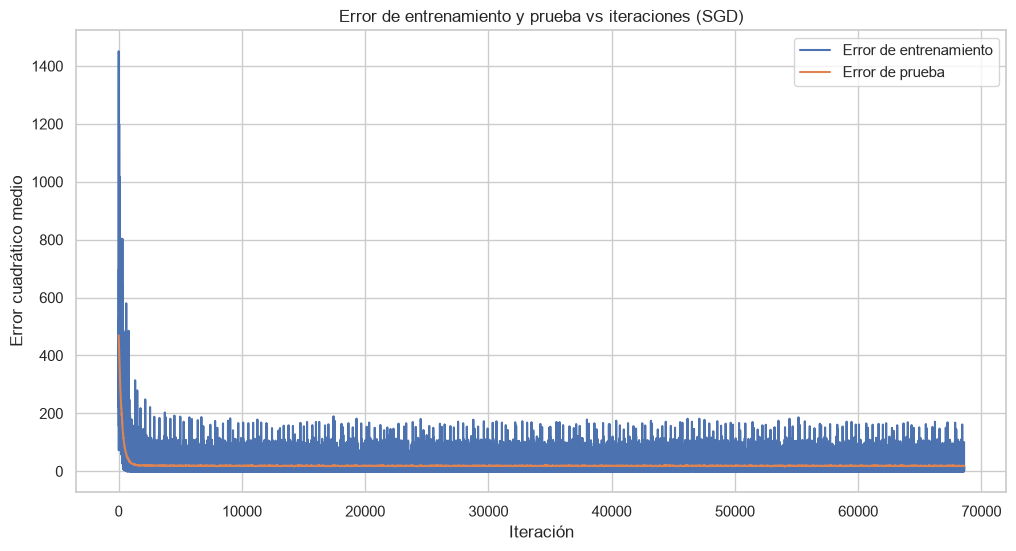

In [63]:
# Gradiente estocástico: una actualización por fila
np.random.seed(SEMILLA)
W_sgd, err_train_sgd, err_val_sgd = stochastic_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.001, epochs=200)

*Figura 9. Gráfico de `stochastic_gradient_descent` con `lr = 0.001`: error de entrenamiento de la fila usada en cada paso y MSE de validación (la función lo rotula como prueba), a lo largo de los 68.600 pasos de las 200 épocas.*

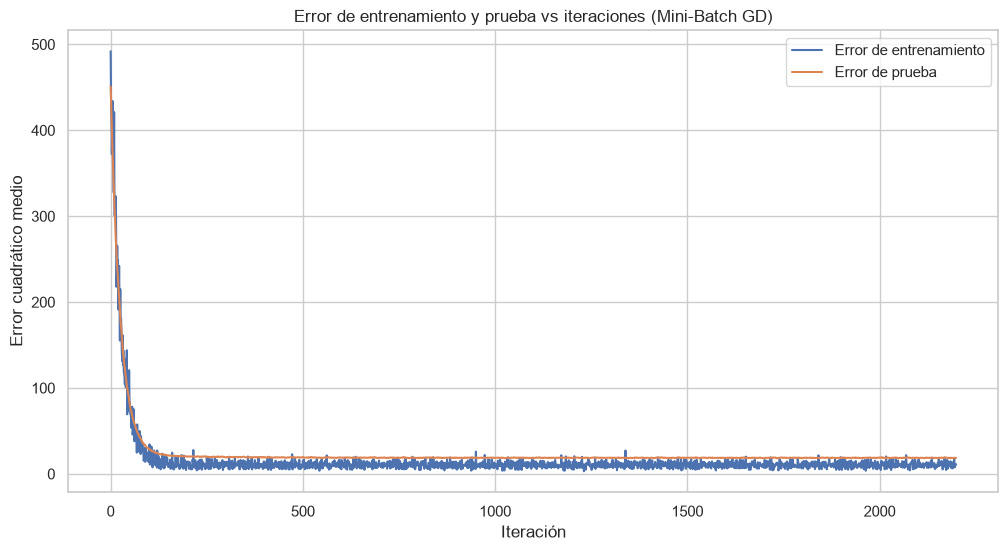

In [64]:
# Mini-batch: una actualización cada 32 filas
np.random.seed(SEMILLA)
W_mb, err_train_mb, err_val_mb = mini_batch_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.01, epochs=200, batch_size=32)

*Figura 10. Gráfico de `mini_batch_gradient_descent` con `lr = 0.01` y lotes de 32 filas: MSE de entrenamiento del lote usado en cada paso y MSE de validación (rotulado como prueba), a lo largo de los 2.200 pasos de las 200 épocas.*

In [65]:
# El error de una sola vivienda con los pesos de mínimos cuadrados, contra las bandas de las Figuras 9 y 10
ultimas_100 = slice(-100 * len(X_train_np), None)
pd.DataFrame({
    "mínimos cuadrados, por vivienda": ((y_train - lineal.predict(X_train_prep)) ** 2).describe(percentiles=[0.5, 0.95]),
    "estocástico, por paso": pd.Series(np.ravel(err_train_sgd)[ultimas_100]).describe(percentiles=[0.5, 0.95]),
    "mini-batch, por paso": pd.Series(err_train_mb[-100 * 11:]).describe(percentiles=[0.5, 0.95]),
}).loc[["min", "50%", "95%", "max"]].round(2)

,"mínimos cuadrados, por vivienda","estocástico, por paso","mini-batch, por paso"
min,0.00,0.00,3.03
50%,3.84,3.90,10.33
95%,45.29,46.59,16.30
max,154.04,186.35,27.19


Las tres funciones grafican el error **por paso**, no por época. En el de lotes da lo mismo,
porque cada paso es una época, pero en los otros dos cambia lo que muestra el gráfico.

En el estocástico cada paso es una sola fila. Las 200 épocas son 68.600 pasos, y la curva de
entrenamiento de la Figura 9 no es el MSE del conjunto sino el error de la vivienda que tocó
en cada paso. Por eso, en vez de aplanarse, queda como una banda que llega casi a 200 hasta el
final. Esa banda no dice que el modelo ande mal: con los pesos de mínimos cuadrados el error de
una sola vivienda ya va de 0 a 154, con el 95% por debajo de 46, y en las últimas 100 épocas
la banda tiene casi la misma forma. Lo que dibuja es cuánto se diferencian las viviendas
entre sí, no cuánto se mueven los pesos. La curva que deja ver hacia dónde va el modelo es la
de validación, que en cada paso se calcula sobre las mismas 49 filas (la función la rotula
como prueba porque así llama al conjunto que recibe en cuarto lugar).

El mini-batch queda en el medio: 11 pasos por época, 2.200 en total, y cada punto de
entrenamiento es el MSE de un lote de 32 filas. Promediar 32 viviendas angosta la banda, que
en las últimas 100 épocas va de 3 a 27, pero no la hace desaparecer.

Graficados así, los tres no se pueden comparar en un mismo eje: en una época el estocástico
corrige los pesos 343 veces y el de lotes, una sola. Para la Figura 11 los llevamos a un valor
por época, el del último paso de cada una. El de entrenamiento tiene que ser el MSE de las 343
filas, no el de la última vivienda o el último lote, y la función sólo calcula el error
completo sobre el conjunto de evaluación. Por eso repetimos las corridas del estocástico y del
mini-batch con el entrenamiento en ese lugar. Con la misma semilla, las dos corridas tienen
que pasar por los mismos pesos: cambia sólo sobre qué se mide.

In [66]:
# Repetimos estocástico y mini-batch evaluando sobre entrenamiento, con la misma semilla
np.random.seed(SEMILLA)
W_sgd_bis, _, err_completo_sgd = stochastic_gradient_descent(X_train_np, y_train_np, X_train_np, y_train_np, lr=0.001, epochs=200, graficar=False)
np.random.seed(SEMILLA)
W_mb_bis, _, err_completo_mb = mini_batch_gradient_descent(X_train_np, y_train_np, X_train_np, y_train_np, lr=0.01, epochs=200, batch_size=32, graficar=False)
print(f"Estocástico: diferencia máxima con los pesos de la primera corrida {np.abs(W_sgd_bis - W_sgd).max():.1e}")
print(f"Mini-batch:  diferencia máxima con los pesos de la primera corrida {np.abs(W_mb_bis - W_mb).max():.1e}")

Estocástico: diferencia máxima con los pesos de la primera corrida 0.0e+00
Mini-batch:  diferencia máxima con los pesos de la primera corrida 0.0e+00


In [67]:
def por_epoca(errores, epocas):
    """Se queda con el error del último paso de cada época."""
    return np.asarray(errores, dtype=float).reshape(epocas, -1)[:, -1]

In [68]:
# El MSE de validación de mínimos cuadrados, para usarlo de referencia junto al de entrenamiento
mse_val_ols = np.mean((y_val - lineal.predict(X_val_prep)) ** 2)
print(f"MSE de validación de LinearRegression: {mse_val_ols:.4f}")

MSE de validación de LinearRegression: 18.6773


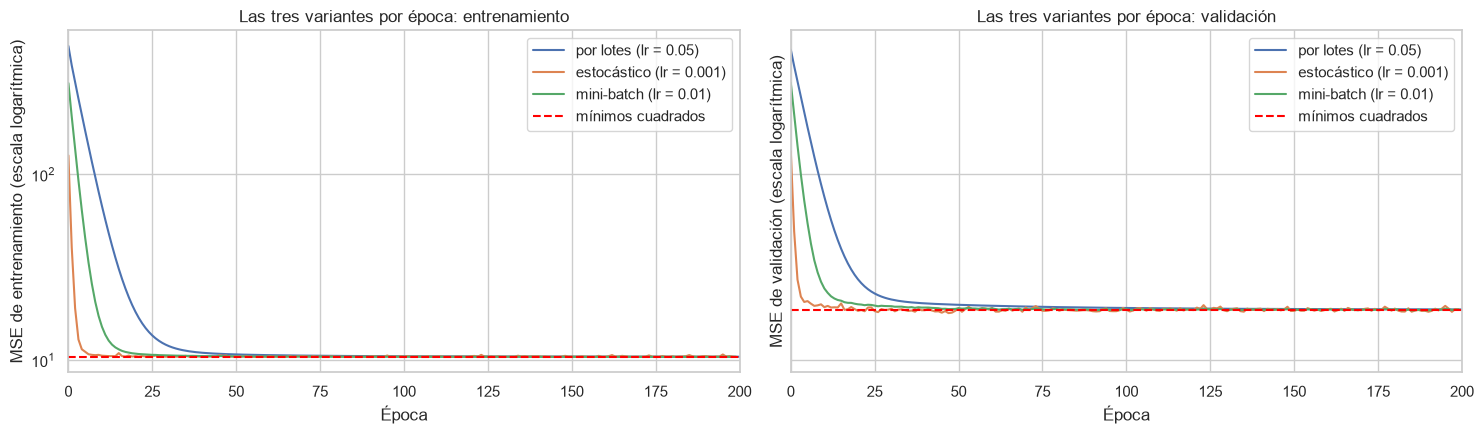

In [69]:
# Las tres variantes con un valor por época, para comparar cuál baja más rápido
curvas_gd = {"por lotes (lr = 0.05)": (err_train_gd, err_val_gd),
             "estocástico (lr = 0.001)": (por_epoca(err_completo_sgd, 200), por_epoca(err_val_sgd, 200)),
             "mini-batch (lr = 0.01)": (por_epoca(err_completo_mb, 200), por_epoca(err_val_mb, 200))}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for nombre, (err_tr, err_va) in curvas_gd.items():
    axes[0].plot(err_tr, label=nombre)
    axes[1].plot(err_va, label=nombre)
for ax, conjunto, referencia in zip(axes, ["entrenamiento", "validación"], [mse_ols, mse_val_ols]):
    ax.axhline(referencia, color="red", ls="--", lw=1.5, label="mínimos cuadrados")
    ax.set_yscale("log")
    ax.set_xlim(0, 200)
    ax.set_xlabel("Época")
    ax.set_ylabel(f"MSE de {conjunto} (escala logarítmica)")
    ax.set_title(f"Las tres variantes por época: {conjunto}")
    ax.legend()
plt.tight_layout()
plt.show()

*Figura 11. MSE de las tres variantes del gradiente en las primeras 200 épocas, en entrenamiento (izquierda, sobre las 343 filas) y en validación (derecha), con el valor del último paso de cada época y en escala logarítmica. Las líneas rojas son el MSE de mínimos cuadrados en cada conjunto.*

In [70]:
# Las tres variantes contra mínimos cuadrados, en los tres conjuntos
def preds_gd(W):
    return {"entrenamiento": predecir(X_train_np, W),
            "validación": predecir(X_val_np, W),
            "prueba": predecir(X_test_np, W)}

comparacion_gd = tabla_comparativa({
    "LinearRegression": {"entrenamiento": pred_train, "validación": pred_val, "prueba": pred_test},
    "GD por lotes": preds_gd(W_gd),
    "GD estocástico": preds_gd(W_sgd),
    "GD mini-batch": preds_gd(W_mb),
})
comparacion_gd

R²    RMSE     MAE
LinearRegression entrenamiento  0.8311  3.2251  2.4527
                 validación     0.6627  4.3217  3.0245
                 prueba         0.7691  3.8779  2.8497
GD por lotes     entrenamiento  0.8311  3.2251  2.4527
                 validación     0.6627  4.3217  3.0245
                 prueba         0.7690  3.8779  2.8497
GD estocástico   entrenamiento  0.8311  3.2255  2.4521
                 validación     0.6620  4.3260  3.0245
                 prueba         0.7703  3.8678  2.8462
GD mini-batch    entrenamiento  0.8311  3.2253  2.4515
                 validación     0.6623  4.3245  3.0259
                 prueba         0.7690  3.8780  2.8501

In [71]:
# Guardamos las tres para la comparación final del ítem 6
resultados["GD por lotes"] = metricas(y_test, predecir(X_test_np, W_gd))
resultados["GD estocástico"] = metricas(y_test, predecir(X_test_np, W_sgd))
resultados["GD mini-batch"] = metricas(y_test, predecir(X_test_np, W_mb))
pd.DataFrame(resultados).round(4)

,LinearRegression,GD por lotes,GD estocástico,GD mini-batch
R²,0.7691,0.7690,0.7703,0.7690
RMSE,3.8779,3.8779,3.8678,3.8780
MAE,2.8497,2.8497,2.8462,2.8501


In [72]:
# Qué tan lejos quedaron los pesos de cada variante de los de mínimos cuadrados
pesos_ols = np.concatenate([[lineal.intercept_], lineal.coef_])
pd.Series({"GD por lotes": np.linalg.norm(W_gd.ravel() - pesos_ols),
           "GD estocástico": np.linalg.norm(W_sgd.ravel() - pesos_ols),
           "GD mini-batch": np.linalg.norm(W_mb.ravel() - pesos_ols)}).to_frame("distancia a mínimos cuadrados").round(4)

,distancia a mínimos cuadrados
GD por lotes,0.0024
GD estocástico,0.0568
GD mini-batch,0.0985


In [73]:
# Con más épocas: si la distancia es ruido no se achica, si es camino que falta recorrer sí
np.random.seed(SEMILLA)
W_sgd_1000, _, _ = stochastic_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.001, epochs=1000, graficar=False)
np.random.seed(SEMILLA)
W_mb_1000, _, _ = mini_batch_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.01, epochs=1000, batch_size=32, graficar=False)
pd.DataFrame({"200 épocas": [np.linalg.norm(W_sgd.ravel() - pesos_ols), np.linalg.norm(W_mb.ravel() - pesos_ols)],
              "1000 épocas": [np.linalg.norm(W_sgd_1000.ravel() - pesos_ols), np.linalg.norm(W_mb_1000.ravel() - pesos_ols)]},
             index=["GD estocástico", "GD mini-batch"]).round(4)

,200 épocas,1000 épocas
GD estocástico,0.0568,0.1699
GD mini-batch,0.0985,0.0460


### ¿Algún cambio?

El gradiente por lotes da un R² de prueba de 0,7690 contra 0,7691 de `LinearRegression`, y
el mismo RMSE hasta el cuarto decimal. Mini-batch queda en 0,7690 y SGD en 0,7703, apenas
por encima. Las cuatro filas de la tabla son en la práctica el mismo modelo.

Y no puede ser de otra manera. Los cuatro métodos minimizan la misma función de costo sobre
los mismos datos, y esa función tiene un solo mínimo, así que todos apuntan al mismo lugar.
La fórmula cerrada va directo, el gradiente se acerca iterando. Si el gradiente nos hubiera
dado un error *menor* que mínimos cuadrados, tendríamos que sospechar de un error en el
código, porque significaría que la fórmula exacta no encontró el óptimo. Que SGD tenga
un error de prueba apenas menor no contradice eso: lo que minimizan es el error de
entrenamiento, y ahí ninguna de las tres baja de mínimos cuadrados. Mínimos cuadrados y el
de lotes dan un RMSE de 3,2251, el mini-batch 3,2253 y SGD 3,2255.

Lo que sí cambia entre las variantes es **cómo** llegan (Figura 11):

- **Por lotes** llega al mínimo y se queda quieto. Usa las 343 filas para calcular cada
  gradiente, así que la dirección es la correcta y la curva baja suave, sin sobresaltos (Figura 8).
- **SGD** no termina de asentarse. Cada paso lo da mirando **una sola vivienda**:
  esa dirección es una estimación muy ruidosa del gradiente verdadero, así que en vez de
  frenar en el mínimo, se la pasa rebotando alrededor. Se nota en la Figura 11, donde su curva después de
  bajar queda temblando en vez de aplanarse. A las 200 épocas sus pesos quedan a una distancia
  de 0,057 de los de mínimos cuadrados (contra 0,0024 del de lotes), y darle más épocas no lo
  acerca: a las 1000 queda a 0,170. Esa distancia no es camino que le falte recorrer, es dónde
  lo agarró el último rebote.
- **Mini-batch** baja suave en la Figura 11, y esa es justamente su razón de ser: promediar 32 filas
  cancela buena parte del ruido de SGD sin pagar el costo de recorrer las 343 en cada paso. A
  las 200 épocas sus pesos quedan más lejos que los de SGD (0,099), pero por otro motivo:
  todavía no terminó de llegar. Hace 11 correcciones por época contra las 343 de SGD, y con
  1000 épocas la distancia baja a 0,046.

En un dataset de 343 filas esa diferencia de costo no se siente y el gradiente por lotes
gana sin discusión. La ventaja de SGD y mini-batch aparece cuando las filas son millones y
recorrerlas todas para dar un solo paso deja de ser viable.

Que converjan depende de haber elegido bien `lr` y épocas, y esa elección **no es gratis**: es
la diferencia grande contra mínimos cuadrados, que no tiene nada que elegir. Con un `lr`
demasiado chico el método no llegaría en las épocas que le damos, y con uno demasiado grande
podría escaparse.

## Regularización: Ridge, Lasso y Elastic Net

Mínimos cuadrados busca los pesos que hacen mínima la suma de los errores al cuadrado, y
nada más. La regularización le agrega a esa cuenta un segundo término que penaliza el
**tamaño** de los pesos, así que el modelo tiene que negociar entre dos cosas: ajustar bien
y no usar coeficientes grandes. Cuánto pesa esa segunda condición lo decide un
hiperparámetro, `alpha`.

Las tres variantes se diferencian en cómo miden el tamaño de los pesos:

**Ridge** penaliza la suma de los cuadrados (norma L2):

$$J(W) = \sum_{i}(y_i - \hat{y}_i)^2 + \alpha \sum_{j} w_j^2$$

Como la penalización crece con el cuadrado, castiga mucho a los coeficientes grandes y poco
a los chicos, así que los achica a todos pero no llega a anular ninguno.

**Lasso** penaliza la suma de los valores absolutos (norma L1):

$$J(W) = \sum_{i}(y_i - \hat{y}_i)^2 + \alpha \sum_{j} |w_j|$$

Acá el castigo es proporcional al tamaño, sin importar qué tan chico sea el coeficiente. Eso
hace que a un peso que aporta poco le convenga irse directamente a **cero**, y por eso Lasso
sirve además para seleccionar variables.

**Elastic Net** mezcla las dos, y `l1_ratio` decide la proporción de cada una: con
`l1_ratio = 1` es Lasso puro, con `l1_ratio = 0` es Ridge puro.

La penalización compara los coeficientes
entre sí, así que **sólo tiene sentido con los datos escalados**: si no, castigaría más a
unas variables que a otras según la unidad en la que están medidas. Ya los tenemos
estandarizados. La ordenada al origen no se penaliza, y está bien que sea así: no
es el peso de ninguna variable, es el nivel general de los precios, y achicarlo sólo
correría todas las predicciones para abajo.

En este ítem los entrenamos con `alpha = 1`, que es el valor por defecto de scikit-learn.
No es una elección nuestra, es un punto de partida para ver cómo se comporta cada uno; la
búsqueda del `alpha` que conviene es el ítem 5.

In [74]:
# Los tres modelos regularizados
from sklearn.linear_model import Ridge, Lasso, ElasticNet

In [75]:
# Los entrenamos con alpha = 1 sobre los mismos datos escalados que usó LinearRegression
ridge = Ridge(alpha=1.0).fit(X_train_prep, y_train)
lasso = Lasso(alpha=1.0).fit(X_train_prep, y_train)
elastic = ElasticNet(alpha=1.0, l1_ratio=0.5).fit(X_train_prep, y_train)

In [76]:
# Métricas de los tres, con LinearRegression al lado para comparar
comparacion_reg = pd.DataFrame({
    "LinearRegression": metricas(y_test, pred_test),
    "Ridge": metricas(y_test, ridge.predict(X_test_prep)),
    "Lasso": metricas(y_test, lasso.predict(X_test_prep)),
    "Elastic Net": metricas(y_test, elastic.predict(X_test_prep)),
}).round(4)
comparacion_reg

,LinearRegression,Ridge,Lasso,Elastic Net
R²,0.7691,0.7694,0.7375,0.7342
RMSE,3.8779,3.8750,4.1344,4.1599
MAE,2.8497,2.8465,3.2466,3.2084


In [77]:
# Los cuatro modelos en los tres conjuntos, con las tres métricas
def preds_modelo(modelo):
    return {"entrenamiento": modelo.predict(X_train_prep),
            "validación": modelo.predict(X_val_prep),
            "prueba": modelo.predict(X_test_prep)}

comparacion_reg_completa = tabla_comparativa({
    "LinearRegression": preds_modelo(lineal), "Ridge": preds_modelo(ridge),
    "Lasso": preds_modelo(lasso), "Elastic Net": preds_modelo(elastic),
})
comparacion_reg_completa

R²    RMSE     MAE
LinearRegression entrenamiento  0.8311  3.2251  2.4527
                 validación     0.6627  4.3217  3.0245
                 prueba         0.7691  3.8779  2.8497
Ridge            entrenamiento  0.8311  3.2253  2.4487
                 validación     0.6629  4.3202  3.0240
                 prueba         0.7694  3.8750  2.8465
Lasso            entrenamiento  0.7550  3.8845  2.9086
                 validación     0.6361  4.4885  3.4029
                 prueba         0.7375  4.1344  3.2466
Elastic Net      entrenamiento  0.7399  4.0024  2.9842
                 validación     0.6425  4.4493  3.4139
                 prueba         0.7342  4.1599  3.2084

In [78]:
# Los coeficientes de los cuatro, uno al lado del otro
coefs = pd.DataFrame({"LinearRegression": lineal.coef_, "Ridge": ridge.coef_,
                      "Lasso": lasso.coef_, "Elastic Net": elastic.coef_},
                     index=X_train_prep.columns)
coefs.round(3)

,LinearRegression,Ridge,Lasso,Elastic Net
CRIM,-1.265,-1.252,-0.252,-0.505
ZN,0.398,0.386,0.000,0.000
INDUS,-0.154,-0.181,-0.000,-0.466
CHAS,0.225,0.227,0.000,0.000
NOX,-0.980,-0.957,-0.000,-0.144
RM,2.147,2.160,1.803,1.902
AGE,-0.376,-0.383,-0.000,-0.163
DIS,-2.321,-2.292,-0.000,-0.000
RAD,2.104,2.020,-0.000,-0.000
TAX,-1.980,-1.901,-0.293,-0.538


In [79]:
# Cuánto achicó los pesos cada penalización, y cuántas variables dejó en cero
pd.DataFrame({"suma de |coeficientes|": coefs.abs().sum().round(2),
              "variables en cero": (coefs.abs() < 1e-8).sum()})

,suma de |coeficientes|,variables en cero
LinearRegression,18.01,0
Ridge,17.79,0
Lasso,6.80,7
Elastic Net,7.11,4


### Lectura

Ridge se comporta casi igual que `LinearRegression`: R² de prueba 0,7694 contra 0,7691,
y la suma de los coeficientes en valor absoluto baja apenas de 18,01 a 17,79. Con `alpha = 1`
la penalización es tan chica frente al término de error que casi no mueve la solución. No
mejora, pero tampoco rompe nada.

Lasso y Elastic Net, en cambio, empeoran bastante. Lasso baja el R² de prueba a 0,7375 y
Elastic Net a 0,7342, y los dos suben el RMSE de 3,88 a más de 4,13. Lo que pasa se ve en la
tabla de coeficientes: con `alpha = 1` Lasso manda **siete de las trece variables a cero** y
Elastic Net cuatro. La suma de los pesos se desploma de 18,01 a 6,80. Esto ya no es achicar
los coeficientes, es amputar el modelo.

Y se nota en la fila de entrenamiento: el R² de Lasso ahí es 0,7550 contra 0,8311 de
`LinearRegression`. **Está subajustando.** No es un problema de generalización sino de que
la penalización le está impidiendo aprender lo que los datos sí tienen para enseñarle. Es
coherente con el diagnóstico que veníamos arrastrando: si el modelo tiene sesgo y no
varianza, agregarle una restricción sólo le suma más sesgo.

Lasso no elige al azar qué variables descarta:

- Manda `RAD` a cero y le deja a `TAX` un coeficiente chico, de −0,293. Es exactamente lo
  que la teoría dice que hace Lasso frente a la colinealidad: cuando dos variables son casi
  intercambiables, elige una y anula la otra, en vez de repartir el peso entre las dos como
  hace Ridge. `RAD` y `TAX` eran nuestro par más colineal (0,904, con los VIF más altos), y
  Lasso lo resolvió quedándose con una sola.
- `ZN` y `CHAS` están entre las primeras que anula. Nos habíamos preguntado si aportaban
  algo, y con este `alpha` la respuesta es que no las considera necesarias. Pero que las descarte con `alpha = 1` no significa que sean inútiles, sino que
  con esta penalización lo que aportan no alcanza para pagar el costo de tenerlas. Con un
  `alpha` más chico podrían sobrevivir.

`LSTAT` sobrevive en los tres modelos y con el coeficiente más grande de todos. En Lasso
incluso queda un poco más grande que en `LinearRegression` (−3,732 contra −3,715): al
quedarse sin varias de las otras variables, absorbe parte de lo que ellas explicaban.

### Cómo cambian los coeficientes con `alpha`

In [80]:
def camino_coeficientes(constructor, alphas):
    """Ajusta el modelo para cada alpha y devuelve todos los coeficientes en un DataFrame."""
    return pd.DataFrame([constructor(a).fit(X_train_prep, y_train).coef_ for a in alphas],
                        index=alphas, columns=X_train_prep.columns)

In [81]:
def graficar_camino(coeficientes, titulo):
    """Grafica cómo evoluciona cada coeficiente a medida que crece alpha."""
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(coeficientes.index, coeficientes.values)
    ax.set_xscale("log")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("alpha (escala logarítmica)")
    ax.set_ylabel("Coeficiente")
    ax.set_title(titulo)
    ax.legend(coeficientes.columns, ncol=2, fontsize=8,
              loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()
    plt.show()

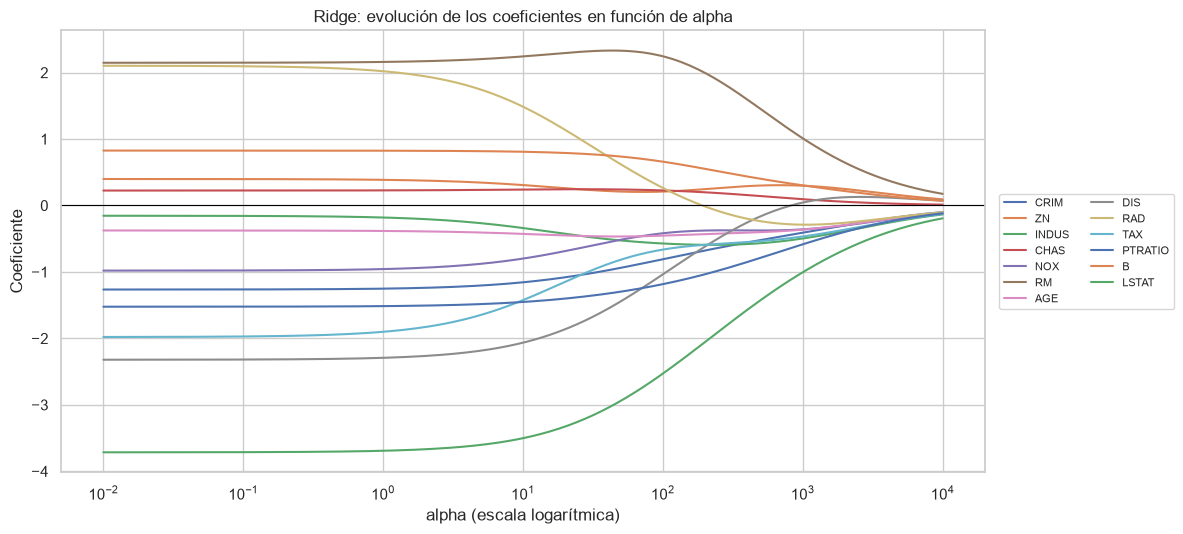

In [82]:
# Ridge sobre seis órdenes de magnitud de alpha
alphas_ridge = np.logspace(-2, 4, 200)
camino_ridge = camino_coeficientes(lambda a: Ridge(alpha=a), alphas_ridge)
graficar_camino(camino_ridge, "Ridge: evolución de los coeficientes en función de alpha")

*Figura 12. Ridge: coeficiente de cada variable en función de `alpha`, de 0,01 a 10.000 en escala logarítmica.*

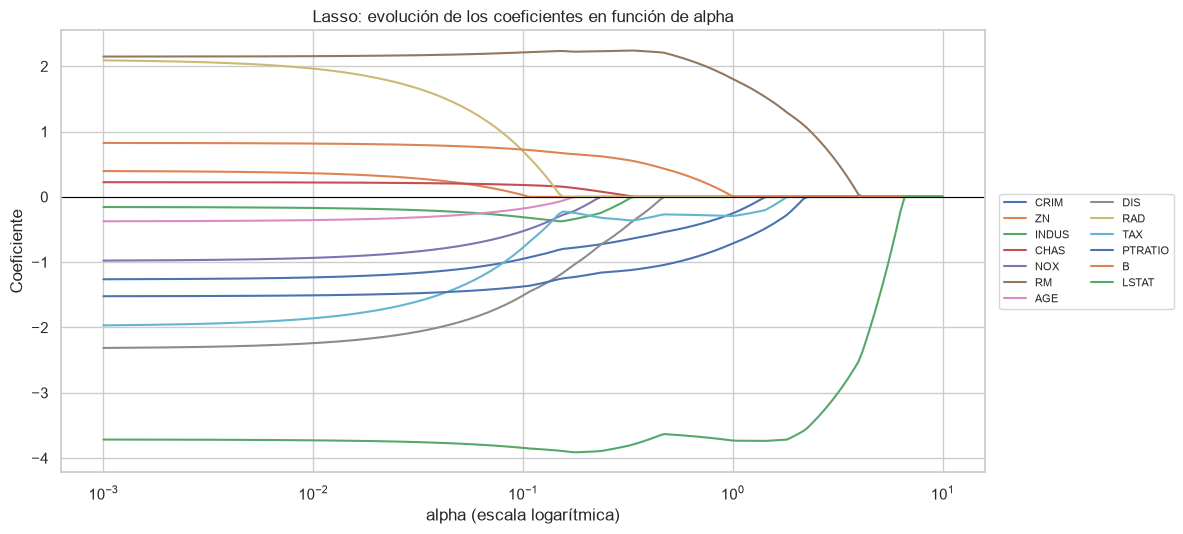

In [83]:
# Lasso sobre el rango donde pasa algo: de no penalizar casi nada a anularlo todo
alphas_lasso = np.logspace(-3, 1, 200)
camino_lasso = camino_coeficientes(lambda a: Lasso(alpha=a, max_iter=10000), alphas_lasso)
graficar_camino(camino_lasso, "Lasso: evolución de los coeficientes en función de alpha")

*Figura 13. Lasso: coeficiente de cada variable en función de `alpha`, de 0,001 a 10 en escala logarítmica.*

In [84]:
# Con Ridge ningún coeficiente llega nunca a cero; con Lasso desaparecen todos
print(f"Coeficientes exactamente nulos con Ridge (alpha hasta {alphas_ridge.max():.0f}): "
      f"{int((camino_ridge.abs() < 1e-10).sum().sum())}")
print(f"Coeficientes exactamente nulos con Lasso (alpha hasta {alphas_lasso.max():.0f}): "
      f"{int((camino_lasso.abs() < 1e-10).sum().sum())}")

Coeficientes exactamente nulos con Ridge (alpha hasta 10000): 0
Coeficientes exactamente nulos con Lasso (alpha hasta 10): 767


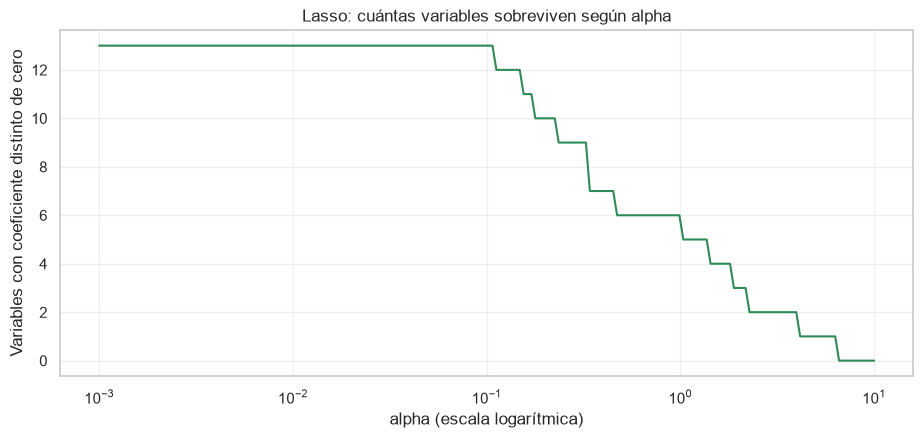

In [85]:
# Cuántas variables le quedan a Lasso según cuánto lo penalicemos
variables_vivas = (camino_lasso.abs() > 1e-10).sum(axis=1)

plt.figure(figsize=(11, 4.5))
plt.plot(variables_vivas.index, variables_vivas.values, color="seagreen")
plt.xscale("log")
plt.xlabel("alpha (escala logarítmica)")
plt.ylabel("Variables con coeficiente distinto de cero")
plt.title("Lasso: cuántas variables sobreviven según alpha")
plt.grid(alpha=0.3)
plt.show()

*Figura 14. Lasso: cantidad de variables con coeficiente distinto de cero para cada `alpha`.*

In [86]:
# El orden en que Lasso las va descartando
def alpha_de_muerte(columna):
    nulos = camino_lasso.index[camino_lasso[columna].abs() < 1e-10]
    return nulos.min() if len(nulos) else np.nan

orden_descarte = pd.Series({c: alpha_de_muerte(c) for c in camino_lasso.columns})
orden_descarte.sort_values().to_frame("alpha al que se anula").round(3)

,alpha al que se anula
ZN,0.112
RAD,0.155
AGE,0.178
NOX,0.235
CHAS,0.341
INDUS,0.341
DIS,0.471
B,1.035
CRIM,1.431
TAX,1.890


In [87]:
# En Ridge, RAD arranca positivo y termina negativo: buscamos dónde cambia de signo
negativos = camino_ridge.index[camino_ridge["RAD"] < 0]
print(f"Coeficiente de RAD sin penalizar:        {lineal.coef_[list(X_train_prep.columns).index('RAD')]:+.3f}")
print(f"Correlación de RAD con MEDV:             {X_train['RAD'].corr(y_train):+.3f}")
print(f"RAD cambia de signo a partir de alpha ≈  {negativos.min():.0f}")

Coeficiente de RAD sin penalizar:        +2.104
Correlación de RAD con MEDV:             -0.475
RAD cambia de signo a partir de alpha ≈  205


### Lectura de los caminos

Las Figuras 12 y 13 muestran la diferencia entre las dos penalizaciones. En Ridge todas las curvas se acercan al cero de forma suave y nunca lo tocan: sobre 200 valores
de `alpha` y 13 variables no hay **ni un solo** coeficiente exactamente nulo, ni siquiera
con `alpha = 10.000`. En Lasso, en cambio, las curvas llegan al cero, lo tocan y se quedan
ahí. Esa es toda la diferencia entre achicar y seleccionar, y se ve de un vistazo.

El orden en que Lasso descarta las variables (Figura 14) es informativo por sí solo. Las primeras en
caer son `ZN` y `RAD`, y las últimas dos en quedar en pie son `RM` y `LSTAT`, que son
justamente las dos más correlacionadas con `MEDV`. Lasso está ordenando las variables por
cuánto aportan, y el orden coincide con lo que venimos viendo en todo el trabajo.

Dentro de ese orden hay dos detalles que nos llamaron la atención:

- `RAD` cae segunda y `TAX` recién décima. Eran nuestro par colineal (correlación 0,904),
  y Lasso los separa: se queda con uno y descarta el otro en cuanto puede. No es que `RAD`
  no sirva, es que con `TAX` adentro no agrega nada que justifique su costo.
- `ZN` cae primera y `CHAS` quinta. Era la pregunta que nos veníamos haciendo desde
  el análisis descriptivo, cuando vimos que `CHAS` tenía una correlación de apenas 0,048.
  Confirmado: son de las que menos aportan.

En el camino de Ridge hay algo que cierra una historia que arrastramos desde el VIF.
`RAD` tiene coeficiente +2,104 sin penalizar, pero su correlación con `MEDV` es **negativa**
(−0,475): era el cambio de signo que atribuimos a la colinealidad con `TAX`. En la Figura 12 se ve cómo, a medida que sube `alpha`, ese coeficiente baja, cruza el cero cerca de
`alpha ≈ 205` y se queda del lado negativo.

O sea que **la regularización deshace el cambio de signo**. Al castigar los coeficientes
grandes, Ridge deja de permitir el arreglo de "`RAD` muy positivo compensado con `TAX` muy
negativo", que es un reparto que ajusta bien el entrenamiento pero que depende de la muestra
que nos tocó. Cuando esa compensación deja de ser gratis, `RAD` se acomoda del lado que
indica su relación real con el precio.

### ¿Ridge estabiliza los coeficientes?

Cuando calculamos el VIF dejamos anotada una hipótesis: que Ridge no nos iba a mejorar mucho
la predicción, pero sí la **estabilidad** de los coeficientes, que era el problema real que
nos marcó la colinealidad en `RAD` y `TAX`. Las métricas de recién confirman la primera
mitad. Falta la segunda, y no se puede ver mirando un solo ajuste: la inestabilidad es
cuánto cambiarían los coeficientes si nos hubiera tocado otra muestra.

Para medirlo armamos 200 muestras distintas del conjunto de entrenamiento, sorteando filas
con reemplazo, y ajustamos los modelos en cada una. Si un coeficiente es estable, va a dar
parecido en las 200; si es inestable, va a saltar. El desvío estándar de esos 200 valores es
la medida directa de lo que el VIF estimaba de forma indirecta.

In [88]:
# Remuestreamos el entrenamiento 200 veces y vemos cuánto salta cada coeficiente
generador = np.random.default_rng(SEMILLA)
modelos = {"LinearRegression": LinearRegression(), "Ridge alpha=1": Ridge(alpha=1),
           "Ridge alpha=10": Ridge(alpha=10), "Ridge alpha=100": Ridge(alpha=100)}
acumulado = {nombre: [] for nombre in modelos}

for _ in range(200):
    filas = generador.integers(0, len(X_train_prep), len(X_train_prep))
    X_muestra, y_muestra = X_train_prep.iloc[filas], y_train.iloc[filas]
    for nombre, modelo in modelos.items():
        acumulado[nombre].append(modelo.fit(X_muestra, y_muestra).coef_)

In [89]:
# Desvío estándar de cada coeficiente a lo largo de las 200 muestras
estabilidad = pd.DataFrame({nombre: np.std(np.array(v), axis=0) for nombre, v in acumulado.items()},
                           index=X_train_prep.columns)
estabilidad["VIF"] = vif["VIF"]
estabilidad.sort_values("VIF", ascending=False).round(3)

,LinearRegression,Ridge alpha=1,Ridge alpha=10,Ridge alpha=100,VIF
TAX,0.512,0.489,0.357,0.136,8.858
RAD,0.483,0.462,0.344,0.139,7.088
NOX,0.371,0.363,0.310,0.144,4.617
INDUS,0.343,0.337,0.293,0.159,4.187
DIS,0.417,0.408,0.345,0.161,4.000
LSTAT,0.662,0.651,0.572,0.260,3.362
AGE,0.454,0.446,0.385,0.188,3.179
ZN,0.306,0.301,0.272,0.180,2.323
RM,0.572,0.567,0.521,0.323,2.076
PTRATIO,0.218,0.215,0.198,0.147,1.765


In [90]:
# Cuánto se redujo la inestabilidad total al regularizar
print("Suma de los desvíos de los 13 coeficientes:")
for nombre in modelos:
    total = estabilidad[nombre].sum()
    print(f"  {nombre:20s} {total:.2f}   ({total / estabilidad['LinearRegression'].sum() - 1:+.0%})")

Suma de los desvíos de los 13 coeficientes:
  LinearRegression     4.99   (+0%)
  Ridge alpha=1        4.88   (-2%)
  Ridge alpha=10       4.17   (-16%)
  Ridge alpha=100      2.23   (-55%)


### Lectura de la estabilidad

La hipótesis se cumple. Con `alpha = 100` la suma de los desvíos baja de 4,99 a 2,23, o
sea que los coeficientes se vuelven **menos de la mitad de volátiles** de lo que eran sin
regularizar. Y no baja parejo: la tabla está ordenada por VIF y las dos primeras filas son
las que más ganan.

`TAX`, con el VIF más alto (8,86), pasa de un desvío de 0,512 a 0,136: una reducción del
73%. `RAD`, el segundo (7,09), va de 0,483 a 0,139, un 71% menos. En el otro extremo, `CHAS`
y `B`, que tienen los VIF más bajos del conjunto (1,05 y 1,26), apenas mejoran un 30%. La
regularización le pega más fuerte justo donde el VIF había señalado el problema, que es
lo que predecía la teoría: Ridge reparte el peso entre las variables
correlacionadas en vez de dejar que el ajuste elija un reparto arbitrario, y eso hace que la
muestra puntual que nos tocó deje de determinar el resultado.

Con `alpha = 1` la mejora es mínima (−2%), lo cual encaja con que las métricas y los
coeficientes tampoco se movían: esa penalización es demasiado chica para hacer algo.

Eso sí, esto es un **intercambio, no algo gratis**. Los coeficientes se vuelven
más estables porque se hacen más chicos y más parecidos entre sí, y eso los aleja del valor
que minimiza el error sobre entrenamiento. Es el compromiso sesgo-varianza en su forma más
concreta: bajamos varianza pagando con sesgo. Que convenga o no depende de para qué
queremos el modelo. Si lo único que nos importa es predecir, acá no gana nada. Si además
queremos leer los coeficientes y decir algo sobre qué encarece una vivienda, un coeficiente
estable vale bastante más que uno que cambia de signo según la muestra.

In [91]:
# Guardamos los tres para la comparación final del ítem 6
resultados["Ridge (alpha=1)"] = metricas(y_test, ridge.predict(X_test_prep))
resultados["Lasso (alpha=1)"] = metricas(y_test, lasso.predict(X_test_prep))
resultados["Elastic Net (alpha=1)"] = metricas(y_test, elastic.predict(X_test_prep))
pd.DataFrame(resultados).round(4)

,LinearRegression,GD por lotes,GD estocástico,GD mini-batch,Ridge (alpha=1),Lasso (alpha=1),Elastic Net (alpha=1)
R²,0.7691,0.7690,0.7703,0.7690,0.7694,0.7375,0.7342
RMSE,3.8779,3.8779,3.8678,3.8780,3.8750,4.1344,4.1599
MAE,2.8497,2.8497,2.8462,2.8501,2.8465,3.2466,3.2084


### Cierre del ítem

Con `alpha = 1` ninguno de los tres mejora a `LinearRegression` en predicción: Ridge empata
y los otros dos pierden. Pero ese `alpha` es el valor por defecto de scikit-learn y no tiene nada que ver con nuestros
datos, así que esto todavía no distingue si el problema es la regularización en sí o la dosis.

# Optimización de hiperparámetros

Todo lo que sigue se elige comparando sobre **validación**. El conjunto de prueba no se toca:
si eligiéramos los hiperparámetros mirándolo, nos quedaríamos con la configuración que mejor
le va a esas 98 filas en particular y la métrica final dejaría de medir generalización.

## Hiperparámetros del gradiente descendente

El gradiente por lotes tiene dos perillas, el paso de aprendizaje y la cantidad de épocas, y no son
independientes: las dos deciden cuánto avanza el método en total. Empezamos por el paso,
dejando las épocas fijas en 1000.

In [92]:
# Probamos pasos de 0.0001 a 0.5 e ignoramos el desborde de los que divergen
pasos = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.15, 0.19, 0.2, 0.5]
filas = []
with np.errstate(over="ignore", invalid="ignore"):
    for lr in pasos:
        np.random.seed(SEMILLA)
        W, err_tr, err_va = gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=lr, epochs=1000, graficar=False)
        filas.append({"lr": lr,
                      "MSE entrenamiento": err_tr[-1] if np.isfinite(err_tr[-1]) else np.inf,
                      "MSE validación": err_va[-1] if np.isfinite(err_va[-1]) else np.inf,
                      "distancia a mínimos cuadrados": np.linalg.norm(W.ravel() - pesos_ols)})
pd.DataFrame(filas).set_index("lr").round(4)

,MSE entrenamiento,MSE validación,distancia a mínimos cuadrados
lr,,,
0.0001,3.211317e+02,3.213099e+02,1.784460e+01
0.0010,1.979350e+01,2.879030e+01,3.785600e+00
0.0100,1.041510e+01,1.873490e+01,4.547000e-01
0.0500,1.040110e+01,1.867730e+01,2.400000e-03
0.1000,1.040110e+01,1.867730e+01,0.000000e+00
0.1500,1.040110e+01,1.867730e+01,0.000000e+00
0.1900,6.175927e+266,6.205982e+266,1.354708e+133
0.2000,inf,inf,inf
0.5000,inf,inf,NaN


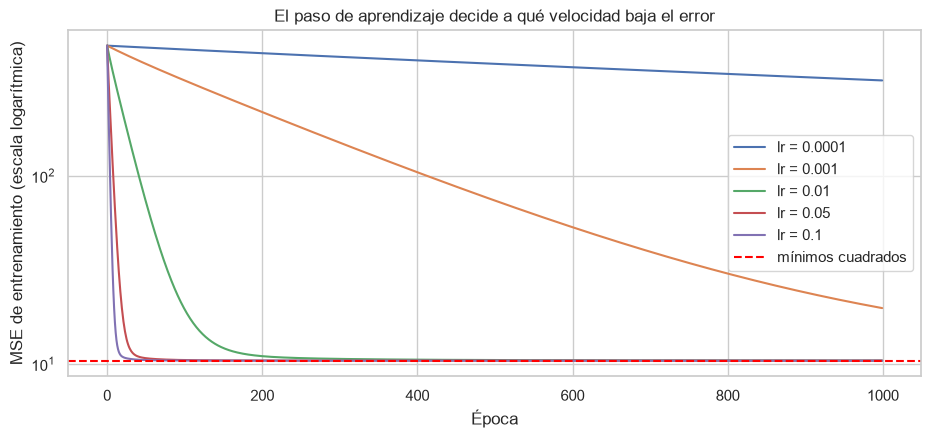

In [93]:
# Las curvas de los pasos que no explotan, para ver a qué velocidad baja cada uno
plt.figure(figsize=(11, 4.5))
for lr in [0.0001, 0.001, 0.01, 0.05, 0.1]:
    np.random.seed(SEMILLA)
    _, err_tr, _ = gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=lr, epochs=1000, graficar=False)
    plt.plot(err_tr, label=f"lr = {lr}")
plt.axhline(mse_ols, color="red", ls="--", lw=1.5, label="mínimos cuadrados")
plt.yscale("log")
plt.xlabel("Época")
plt.ylabel("MSE de entrenamiento (escala logarítmica)")
plt.title("El paso de aprendizaje decide a qué velocidad baja el error")
plt.legend()
plt.show()

*Figura 15. Gradiente por lotes: MSE de entrenamiento en cada época para los cinco pasos de aprendizaje que no divergen, en escala logarítmica, contra el MSE de mínimos cuadrados.*

In [94]:
# Cruzamos paso y épocas, porque un paso chico se puede compensar con más iteraciones
combinaciones = pd.DataFrame(index=[f"lr = {lr}" for lr in (0.001, 0.01, 0.05, 0.1)],
                             columns=[f"{ep} épocas" for ep in (100, 500, 1000, 5000)], dtype=float)
for lr in (0.001, 0.01, 0.05, 0.1):
    for ep in (100, 500, 1000, 5000):
        np.random.seed(SEMILLA)
        _, err_tr, _ = gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=lr, epochs=ep, graficar=False)
        combinaciones.loc[f"lr = {lr}", f"{ep} épocas"] = err_tr[-1]
combinaciones.round(4)

,100 épocas,500 épocas,1000 épocas,5000 épocas
lr = 0.001,322.1451,74.0041,19.7935,10.4786
lr = 0.01,19.7985,10.4786,10.4151,10.4011
lr = 0.05,10.4790,10.4014,10.4011,10.4011
lr = 0.1,10.4152,10.4011,10.4011,10.4011


### Qué observamos

Hay un rango de pasos que funciona y afuera de ese rango el método falla, pero falla de dos
maneras distintas según para qué lado se salga.

Con `lr = 0.0001` el MSE después de 1000 épocas es 321, contra 10,40 de mínimos cuadrados.
No es que el método esté mal: está bajando (Figura 15), sólo que da pasos tan cortos que 1000 épocas no
le alcanzan ni para acercarse. Con `lr = 0.001` llega a 19,79, mejor pero todavía lejos. Es
el modo de fallar más traicionero, porque no da error ni warning: devuelve pesos, y son
malos.

Entre 0,05 y 0,15 el método converge al mismo punto que la fórmula cerrada, con distancias
al vector de mínimos cuadrados de 0,0024 o menos. Ahí adentro da igual cuál se elija, y validación
lo confirma: los tres dan un MSE de validación de 18,6773, el mismo que mínimos cuadrados
(su RMSE de validación, 4,3217, al cuadrado). Una vez que convergen son el mismo modelo, así
que tampoco afuera del entrenamiento hay algo que los distinga.

Pasando 0,15 se rompe de golpe. Con `lr = 0.19` el MSE final es un número de 267 cifras, y
con 0,2 directamente da infinito. Lo que pasa es que el paso es tan largo que el método se
pasa del mínimo y cae más arriba de donde estaba; en la iteración siguiente se pasa todavía
más, y el error crece sin techo. Es el modo de fallar más visible
de los dos, y por suerte el menos peligroso: un `nan` no se confunde con un resultado.

La tabla cruzada muestra que paso y épocas se compensan hasta cierto punto. `lr = 0.001` con
5000 épocas llega a 10,48 y `lr = 0.1` con 500 ya está en 10,4011: casi el mismo destino
con diez veces menos épocas. Pero la compensación no es total. A un `lr` arriba de 0,15 no lo arreglan más épocas:
como cada paso lo deja más lejos del mínimo que el anterior, más épocas sólo agrandan el error.

Nos quedamos con `lr = 0.05` y 1000 épocas, que está cómodamente adentro de la zona que
converge y no depende de haber acertado el valor justo.

### Tamaño del lote

El mini-batch tiene una perilla más, la cantidad de filas que usa en cada actualización. La
variamos entre 1 y 343 con el paso fijo en 0,01 y las épocas en 200, que son los valores del
mini-batch del ítem 4, para que lo único que cambie sea el lote.

Si el mini-batch es un punto medio entre los otros dos métodos, los extremos del rango
deberían ser esos métodos: con una fila por lote actualiza vivienda por vivienda, como el
estocástico, y con 343 usa todo el entrenamiento en cada paso, como el de lotes.

In [95]:
# Comprobamos que los extremos del mini-batch dan los mismos pesos que los otros dos métodos
np.random.seed(SEMILLA)
W_lote_1, _, _ = mini_batch_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.01, epochs=200, batch_size=1, graficar=False)
np.random.seed(SEMILLA)
W_sgd_mismo, _, _ = stochastic_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.01, epochs=200, graficar=False)
np.random.seed(SEMILLA)
W_lote_343, _, _ = mini_batch_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.01, epochs=200, batch_size=len(X_train_np), graficar=False)
np.random.seed(SEMILLA)
W_gd_mismo, _, _ = gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np, lr=0.01, epochs=200, graficar=False)
print(f"Lote de 1 contra estocástico:   diferencia máxima entre pesos {np.abs(W_lote_1 - W_sgd_mismo).max():.1e}")
print(f"Lote de 343 contra por lotes:   diferencia máxima entre pesos {np.abs(W_lote_343 - W_gd_mismo).max():.1e}")

Lote de 1 contra estocástico:   diferencia máxima entre pesos 0.0e+00
Lote de 343 contra por lotes:   diferencia máxima entre pesos 4.4e-16


La diferencia es exactamente cero en un caso y del orden de 10⁻¹⁶, que es error de redondeo, en
el otro: los extremos no se parecen a los otros dos métodos, son los mismos. Las tres funciones arrancan de los mismos pesos
porque las corremos con la misma semilla, y con una fila por lote el mini-batch recorre las viviendas en
el mismo orden que el estocástico. El estocástico y el de lotes son las dos puntas de una misma
familia, y el tamaño del lote es lo que se mueve entre ellas.

In [96]:
# Barremos el tamaño del lote, midiendo por época en validación y en entrenamiento igual que en la Figura 11
LOTES = [1, 8, 32, 128, 343]
curvas_lote = {}
filas = []
for lote in LOTES:
    np.random.seed(SEMILLA)
    W, _, pasos_va = mini_batch_gradient_descent(X_train_np, y_train_np, X_val_np, y_val_np,
                                                 lr=0.01, epochs=200, batch_size=lote, graficar=False)
    np.random.seed(SEMILLA)
    _, _, pasos_tr = mini_batch_gradient_descent(X_train_np, y_train_np, X_train_np, y_train_np,
                                                 lr=0.01, epochs=200, batch_size=lote, graficar=False)
    err_tr, err_va = por_epoca(pasos_tr, 200), por_epoca(pasos_va, 200)
    curvas_lote[lote] = (err_tr, err_va)
    llega = np.flatnonzero(np.array(err_tr) <= 1.01 * mse_ols)
    filas.append({"lote": lote,
                  "actualizaciones por época": int(np.ceil(len(X_train_np) / lote)),
                  "épocas hasta 1% del óptimo": llega[0] if len(llega) else pd.NA,
                  "MSE entrenamiento": err_tr[-1],
                  "MSE validación": err_va[-1],
                  "rango validación (últimas 50)": np.ptp(err_va[-50:]),
                  "distancia a mínimos cuadrados": np.linalg.norm(W.ravel() - pesos_ols)})
pd.DataFrame(filas).set_index("lote").astype({"épocas hasta 1% del óptimo": "Int64"}).round(4)

,actualizaciones por época,épocas hasta 1% del óptimo,MSE entrenamiento,MSE validación,rango validación (últimas 50),distancia a mínimos cuadrados
lote,,,,,,
1,343,<NA>,11.5238,22.8928,13.3092,1.0740
8,43,11,10.4060,18.7471,1.9917,0.0785
32,11,40,10.4022,18.7011,0.3666,0.0985
128,3,162,10.4670,19.0244,0.2397,0.8923
343,1,<NA>,10.9871,20.2266,1.1301,1.8397


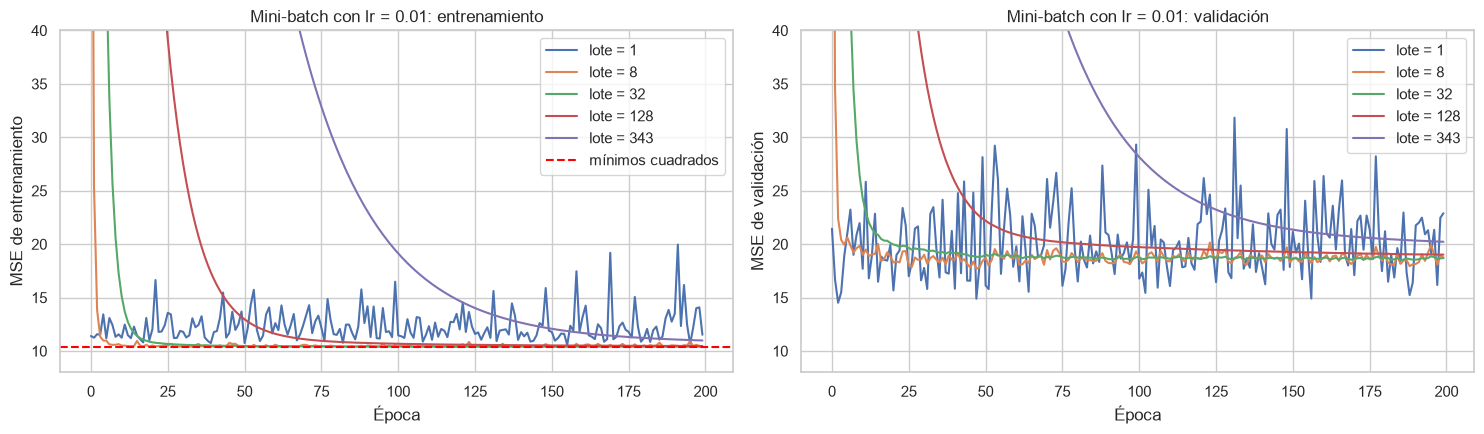

In [97]:
# Curvas de error de cada tamaño de lote, en entrenamiento y en validación
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for lote, (err_tr, err_va) in curvas_lote.items():
    axes[0].plot(err_tr, label=f"lote = {lote}")
    axes[1].plot(err_va, label=f"lote = {lote}")
axes[0].axhline(mse_ols, color="red", ls="--", lw=1.5, label="mínimos cuadrados")
for ax, conjunto in zip(axes, ["entrenamiento", "validación"]):
    ax.set_ylim(8, 40)
    ax.set_xlabel("Época")
    ax.set_ylabel(f"MSE de {conjunto}")
    ax.set_title(f"Mini-batch con lr = 0.01: {conjunto}")
    ax.legend()
plt.tight_layout()
plt.show()

*Figura 16. Mini-batch con `lr = 0.01`: MSE en cada época para cada tamaño de lote, en entrenamiento (izquierda) y en validación (derecha). El eje vertical está recortado entre 8 y 40 para que se vean las oscilaciones.*

El lote decide cuántas veces se corrigen los pesos en cada época, y eso se ve en la velocidad.
Con lotes de 8 hay 43 actualizaciones por época y el error de entrenamiento queda a menos de
1% del de mínimos cuadrados en la época 11; con 32 hay 11 actualizaciones y llega en la 40;
con 128, en la 162. Con 343 hay una sola actualización por época y en 200 épocas no llega
(termina en 10,9871 contra 10,4011): es el gradiente por lotes con un paso de 0,01, que en la
tabla cruzada recién baja a 10,48 a las 500 épocas.

Lo que se gana en velocidad se paga en ruido. Con un lote de 1 el error nunca se asienta: en el panel de entrenamiento de la Figura 16 la curva sigue saltando por encima de la línea de mínimos cuadrados
hasta el final, y en ninguna de las 200 épocas llega a estar a menos de 1% del óptimo. En
validación salta todavía más, con un rango de 13,31 en las últimas 50 épocas. Con 8 el rango
baja a 1,99 y con 32 a 0,37. Es lo mismo que veíamos con el estocástico en el ítem 4: cada paso
mira pocas viviendas, y la dirección que sale de ahí es una estimación ruidosa del gradiente.
En 128 y 343 el rango no es ruido: las curvas todavía están bajando.

El lote de 1 tiene el peor MSE de la tabla en los dos conjuntos (11,52 en entrenamiento y
22,89 en validación), pero ese número dice poco sobre el lote. Es donde quedaron los
pesos después de la última vivienda que miró, y con un rango de 13,31 en las últimas 50 épocas,
parar unas épocas antes o después lo cambia por completo, como se ve en el panel de validación
de la Figura 16: en algunas épocas baja hasta 15, por debajo incluso de mínimos cuadrados
(18,68). Con 49 filas de validación, lo que mide es la suerte de
la época 200 y no el tamaño del lote.

Por eso elegimos por validación, pero sólo entre los lotes cuyo error ya se estabilizó, que
son los únicos donde el valor de la última época dice algo del lote. Quedan afuera 1 y 8, que
siguen oscilando, y 128 y 343, que todavía no terminaron de bajar. Nos quedamos con 32, el
mismo del ítem 4: llega al óptimo en 40 épocas, en validación ya casi no se mueve (rango de
0,37) y tiene el MSE de validación más bajo de los cinco (18,70). Como
el lote no cambia, el mini-batch que entra en la comparación final es el mismo.

## Hiperparámetros de Ridge y Lasso

`alpha` decide cuánto pesa la penalización contra el error de ajuste. Con `alpha` cerca de
cero el modelo es mínimos cuadrados; con `alpha` muy grande todos los coeficientes se van a
cero y el modelo predice siempre el promedio. En el medio está el valor que conviene, y lo
buscamos con el error sobre validación.

In [98]:
# Barremos alpha en Ridge y medimos el error en entrenamiento y en validación
alphas_barrido = np.logspace(-2, 4, 200)
barrido_ridge = pd.DataFrame({"alpha": alphas_barrido})
barrido_ridge["RMSE entrenamiento"] = [
    root_mean_squared_error(y_train, Ridge(alpha=a).fit(X_train_prep, y_train).predict(X_train_prep))
    for a in alphas_barrido]
barrido_ridge["RMSE validación"] = [
    root_mean_squared_error(y_val, Ridge(alpha=a).fit(X_train_prep, y_train).predict(X_val_prep))
    for a in alphas_barrido]
alpha_ridge = barrido_ridge.loc[barrido_ridge["RMSE validación"].idxmin(), "alpha"]
print(f"Mejor alpha para Ridge: {alpha_ridge:.2f}")

Mejor alpha para Ridge: 95.48


In [99]:
def graficar_barrido(barrido, alpha_elegido, titulo):
    """Curva de error contra alpha, con el valor elegido marcado"""
    plt.figure(figsize=(11, 4.5))
    for columna in barrido.columns[1:]:
        plt.plot(barrido["alpha"], barrido[columna], label=columna)
    plt.axvline(alpha_elegido, color="gray", ls="--", label=f"elegido: {alpha_elegido:.4g}")
    plt.xscale("log")
    plt.xlabel("alpha (escala logarítmica)")
    plt.ylabel("RMSE")
    plt.title(titulo)
    plt.legend()
    plt.show()

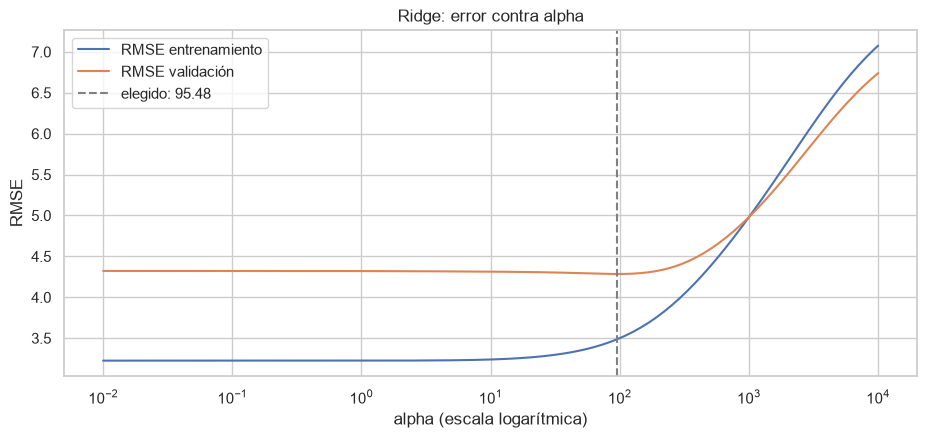

In [100]:
# La curva de Ridge, donde se ve el mínimo de validación
graficar_barrido(barrido_ridge, alpha_ridge, "Ridge: error contra alpha")

*Figura 17. Ridge: RMSE de entrenamiento y de validación en función de `alpha`. La línea gris marca el `alpha` elegido.*

In [101]:
# Mismo barrido para Lasso, agregando cuántas variables deja vivas
alphas_lasso_barrido = np.logspace(-4, 1, 200)
barrido_lasso = pd.DataFrame({"alpha": alphas_lasso_barrido})
ajustes_lasso = [Lasso(alpha=a, max_iter=10000).fit(X_train_prep, y_train) for a in alphas_lasso_barrido]
barrido_lasso["RMSE entrenamiento"] = [root_mean_squared_error(y_train, m.predict(X_train_prep)) for m in ajustes_lasso]
barrido_lasso["RMSE validación"] = [root_mean_squared_error(y_val, m.predict(X_val_prep)) for m in ajustes_lasso]
alpha_lasso = barrido_lasso.loc[barrido_lasso["RMSE validación"].idxmin(), "alpha"]
variables_lasso = int((np.abs(ajustes_lasso[barrido_lasso["RMSE validación"].idxmin()].coef_) > 1e-10).sum())
print(f"Mejor alpha para Lasso: {alpha_lasso:.5f}  |  variables que sobreviven: {variables_lasso} de 13")

Mejor alpha para Lasso: 0.07753  |  variables que sobreviven: 13 de 13


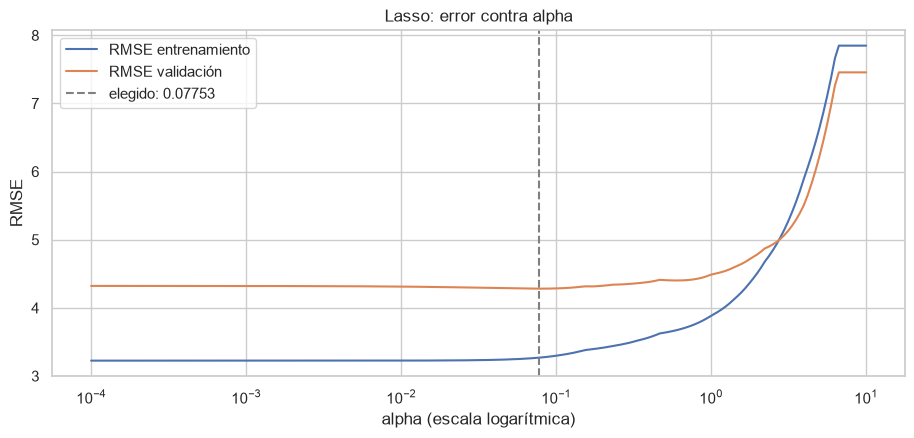

In [102]:
# La curva de Lasso
graficar_barrido(barrido_lasso, alpha_lasso, "Lasso: error contra alpha")

*Figura 18. Lasso: RMSE de entrenamiento y de validación en función de `alpha`. La línea gris marca el `alpha` elegido.*

In [103]:
# Elastic Net tiene dos perillas, así que barremos alpha para cada l1_ratio
proporciones = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
resultados_en = [{"l1_ratio": l1, "alpha": a,
                  "RMSE validación": root_mean_squared_error(
                      y_val, ElasticNet(alpha=a, l1_ratio=l1, max_iter=10000)
                      .fit(X_train_prep, y_train).predict(X_val_prep))}
                 for l1 in proporciones for a in np.logspace(-4, 1, 60)]
barrido_en = pd.DataFrame(resultados_en)
mejor_en = barrido_en.loc[barrido_en["RMSE validación"].idxmin()]
print(f"Mejor Elastic Net: alpha = {mejor_en.alpha:.5f}, l1_ratio = {mejor_en.l1_ratio}")

Mejor Elastic Net: alpha = 0.07609, l1_ratio = 0.99


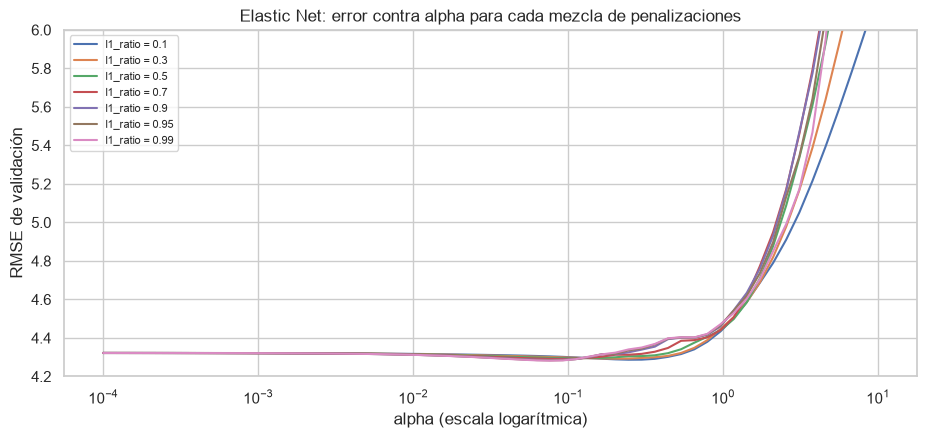

In [104]:
# Una curva por l1_ratio, para ver si la mezcla cambia algo
plt.figure(figsize=(11, 4.5))
for l1 in proporciones:
    sub = barrido_en[barrido_en["l1_ratio"] == l1]
    plt.plot(sub["alpha"], sub["RMSE validación"], label=f"l1_ratio = {l1}")
plt.xscale("log")
plt.ylim(4.2, 6)
plt.xlabel("alpha (escala logarítmica)")
plt.ylabel("RMSE de validación")
plt.title("Elastic Net: error contra alpha para cada mezcla de penalizaciones")
plt.legend(fontsize=8)
plt.show()

*Figura 19. Elastic Net: RMSE de validación en función de `alpha`, con una curva por cada `l1_ratio`.*

### Qué observamos

Las tres curvas (Figuras 17, 18 y 19) tienen la misma forma de pileta y las tres cuentan la misma historia en tres
tramos.

A la izquierda, con `alpha` chico, la curva de validación es plana y coincide con mínimos
cuadrados: la penalización es tan débil que no cambia nada. Es lo que estábamos haciendo con
`alpha = 1` en Ridge, que por eso daba lo mismo que no regularizar.

En el medio hay un mínimo, pero es un mínimo muy poco marcado. Ridge baja el RMSE de
validación de 4,3217 a 4,2844 y Lasso a 4,2813. Son mejoras de menos de cuatro centésimas de
mil dólares sobre un error de más de cuatro mil: existen, pero son chicas.

A la derecha las dos curvas se disparan, y ahí se ve la diferencia entre las dos
penalizaciones. Ridge aguanta hasta `alpha` de varios cientos antes de empeorar; Lasso se
rompe apenas pasa de 1, porque para entonces ya anuló casi todas las variables.

El `alpha` óptimo de Ridge (95,5) es cien veces más grande que el que habíamos usado, y el
de Lasso (0,0775) es trece veces más chico. Los dos estaban mal por el mismo motivo: `alpha`
no es comparable entre las dos penalizaciones, porque una suma cuadrados y la otra valores
absolutos, así que el mismo número significa fuerzas muy distintas.

En su mejor `alpha`, **Lasso conserva las 13 variables**. La pregunta que veníamos
arrastrando sobre `ZN` y `CHAS` queda contestada: son las primeras que Lasso descarta cuando
se lo aprieta, pero con la penalización que el error de validación prefiere no descarta
ninguna. Aportan poco, y ese poco es positivo.

En Elastic Net, las curvas de los distintos `l1_ratio` se superponen casi por completo y el
mejor resultado está en `l1_ratio = 0.99`, que es Lasso con un detalle de Ridge. Como el
mínimo de Lasso y el de Ridge dan prácticamente lo mismo, la mezcla no tiene nada que
aportar: no hay un punto intermedio que sea mejor que los dos extremos.

In [105]:
# Reentrenamos los tres con el alpha que eligió validación
ridge_opt = Ridge(alpha=alpha_ridge).fit(X_train_prep, y_train)
lasso_opt = Lasso(alpha=alpha_lasso, max_iter=10000).fit(X_train_prep, y_train)
elastic_opt = ElasticNet(alpha=mejor_en.alpha, l1_ratio=mejor_en.l1_ratio, max_iter=10000).fit(X_train_prep, y_train)

In [106]:
# Los tres optimizados en los tres conjuntos
tabla_comparativa({
    "LinearRegression": preds_modelo(lineal),
    f"Ridge (alpha={alpha_ridge:.1f})": preds_modelo(ridge_opt),
    f"Lasso (alpha={alpha_lasso:.4f})": preds_modelo(lasso_opt),
    f"Elastic Net (alpha={mejor_en.alpha:.4f})": preds_modelo(elastic_opt),
})

R²    RMSE     MAE
LinearRegression           entrenamiento  0.8311  3.2251  2.4527
                           validación     0.6627  4.3217  3.0245
                           prueba         0.7691  3.8779  2.8497
Ridge (alpha=95.5)         entrenamiento  0.8026  3.4871  2.5806
                           validación     0.6685  4.2844  3.0508
                           prueba         0.7725  3.8492  2.9035
Lasso (alpha=0.0775)       entrenamiento  0.8265  3.2687  2.4532
                           validación     0.6690  4.2813  2.9761
                           prueba         0.7689  3.8795  2.8853
Elastic Net (alpha=0.0761) entrenamiento  0.8267  3.2671  2.4521
                           validación     0.6689  4.2817  2.9768
                           prueba         0.7690  3.8781  2.8828

In [107]:
# Qué le hizo el alpha óptimo al par colineal que nos venía molestando
pd.DataFrame({"LinearRegression": lineal.coef_, "Ridge optimizado": ridge_opt.coef_,
              "Lasso optimizado": lasso_opt.coef_},
             index=X_train_prep.columns).loc[["RAD", "TAX", "LSTAT", "RM"]].round(3)

,LinearRegression,Ridge optimizado,Lasso optimizado
RAD,2.104,0.286,1.014
TAX,-1.980,-0.671,-1.046
LSTAT,-3.715,-2.559,-3.815
RM,2.147,2.255,2.198


In [108]:
# Guardamos los optimizados para la comparación final
resultados[f"Ridge (alpha={alpha_ridge:.1f})"] = metricas(y_test, ridge_opt.predict(X_test_prep))
resultados[f"Lasso (alpha={alpha_lasso:.4f})"] = metricas(y_test, lasso_opt.predict(X_test_prep))
resultados[f"Elastic Net (alpha={mejor_en.alpha:.4f})"] = metricas(y_test, elastic_opt.predict(X_test_prep))
print(f"Modelos acumulados para comparar: {len(resultados)}")

Modelos acumulados para comparar: 10


Con el `alpha` bien elegido, Ridge pasa a ser el mejor de los cuatro en prueba: R² de
0,7725 contra 0,7691 y RMSE de 3,8492 contra 3,8779. Sigue siendo una diferencia chica, pero
ahora va en la dirección correcta, mientras que con `alpha = 1` la regularización sólo
empeoraba o no hacía nada.

El precio se ve en la fila de entrenamiento: Ridge baja de 0,8311 a 0,8026. Eso es el
intercambio sesgo-varianza funcionando como debe. El modelo ajusta peor lo que ya vio a
cambio de ajustar mejor lo que no vio, y la ganancia neta es positiva aunque chica.

En los coeficientes el cambio sí es grande. `RAD` baja de 2,104 a 0,286 y `TAX` de −1,980 a
−0,671. El reparto inflado entre las dos variables colineales se desarmó, y con él la parte
del modelo que menos confianza nos daba.

# Comparación de modelos

Comparamos los diez modelos sobre el conjunto de prueba, que hasta acá no se usó para tomar
ninguna decisión. Entran los tres regularizados con `alpha = 1` y también los tres con el
`alpha` elegido por validación, porque la diferencia entre unos y otros es parte de lo que
hay que comparar.

In [109]:
# Todos los modelos entrenados, ordenados por error en prueba
comparacion_final = pd.DataFrame(resultados).T.sort_values("RMSE")
comparacion_final.round(4)

,R²,RMSE,MAE
Ridge (alpha=95.5),0.7725,3.8492,2.9035
GD estocástico,0.7703,3.8678,2.8462
Ridge (alpha=1),0.7694,3.8750,2.8465
LinearRegression,0.7691,3.8779,2.8497
GD por lotes,0.7690,3.8779,2.8497
GD mini-batch,0.7690,3.8780,2.8501
Elastic Net (alpha=0.0761),0.7690,3.8781,2.8828
Lasso (alpha=0.0775),0.7689,3.8795,2.8853
Lasso (alpha=1),0.7375,4.1344,3.2466
Elastic Net (alpha=1),0.7342,4.1599,3.2084


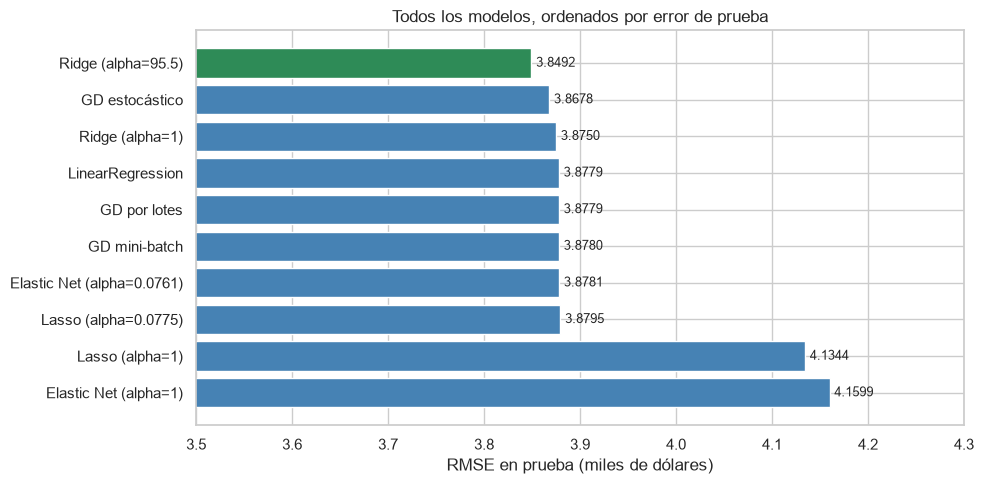

In [110]:
# El mismo ranking en un gráfico, que se lee más rápido
orden = comparacion_final.sort_values("RMSE", ascending=False)
colores = ["seagreen" if i == len(orden) - 1 else "steelblue" for i in range(len(orden))]

plt.figure(figsize=(10, 5))
plt.barh(orden.index, orden["RMSE"], color=colores)
plt.xlim(3.5, 4.3)
plt.xlabel("RMSE en prueba (miles de dólares)")
plt.title("Todos los modelos, ordenados por error de prueba")
for i, v in enumerate(orden["RMSE"]):
    plt.text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

*Figura 20. RMSE de prueba de los diez modelos, del mejor (arriba) al peor (abajo). En verde, el mejor. El eje horizontal arranca en 3,5.*

In [111]:
# Predicciones de prueba de los diez modelos, con los mismos nombres que en la comparación
predicciones_prueba = {
    "LinearRegression": pred_test,
    "GD por lotes": predecir(X_test_np, W_gd),
    "GD estocástico": predecir(X_test_np, W_sgd),
    "GD mini-batch": predecir(X_test_np, W_mb),
    "Ridge (alpha=1)": ridge.predict(X_test_prep),
    "Lasso (alpha=1)": lasso.predict(X_test_prep),
    "Elastic Net (alpha=1)": elastic.predict(X_test_prep),
    f"Ridge (alpha={alpha_ridge:.1f})": ridge_opt.predict(X_test_prep),
    f"Lasso (alpha={alpha_lasso:.4f})": lasso_opt.predict(X_test_prep),
    f"Elastic Net (alpha={mejor_en.alpha:.4f})": elastic_opt.predict(X_test_prep),
}
assert set(predicciones_prueba) == set(comparacion_final.index)

In [112]:
def graficar_predicho_vs_real(ax, y_real, y_pred, titulo, color="steelblue", limites=(-10, 50)):
    """Un panel de predicho contra real, con la diagonal de la predicción perfecta."""
    ax.scatter(y_real, y_pred, alpha=0.6, s=18, color=color)
    ax.plot(limites, limites, "r--", lw=1.5)
    ax.set_xlim(limites)
    ax.set_ylim(limites)
    ax.set_aspect("equal")
    ax.set_xlabel("MEDV real")
    ax.set_ylabel("MEDV predicho")
    ax.set_title(titulo, fontsize=10)

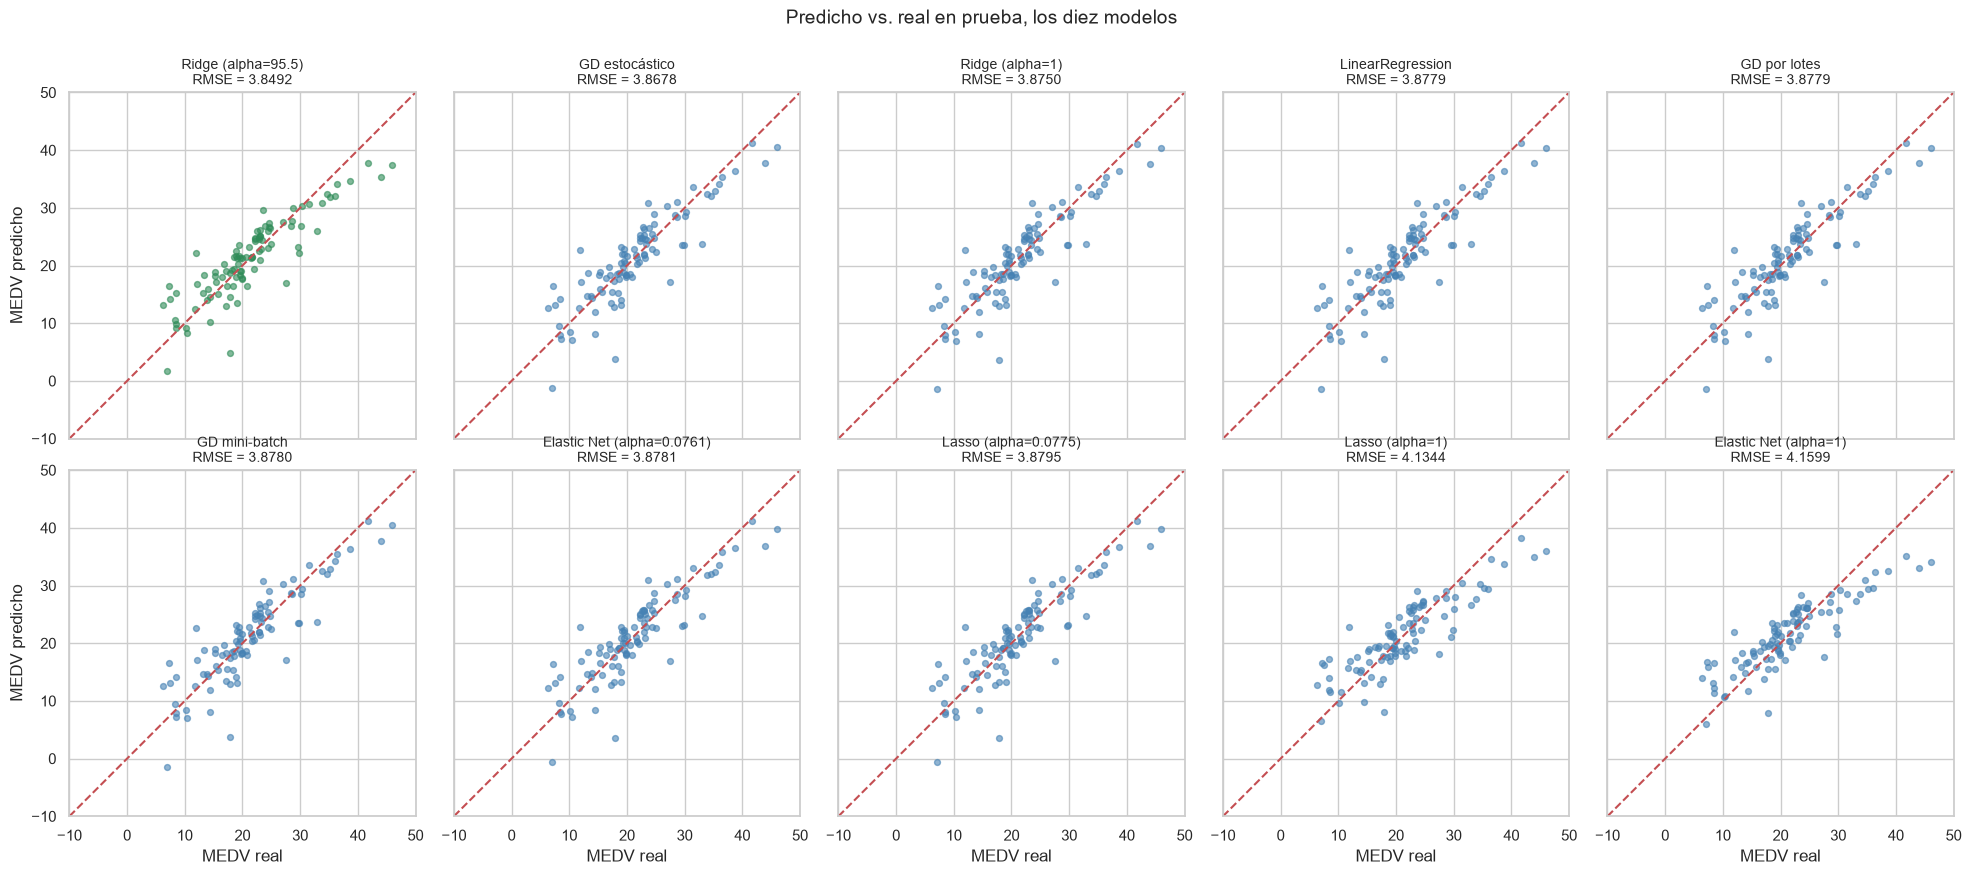

In [113]:
# Los diez modelos en el orden de la tabla, del mejor al peor, todos con los mismos ejes
fig, axes = plt.subplots(2, 5, figsize=(20, 8.5), sharex=True, sharey=True)
for i, (ax, nombre) in enumerate(zip(axes.ravel(), comparacion_final.index)):
    graficar_predicho_vs_real(ax, y_test, predicciones_prueba[nombre],
                              f"{nombre}\nRMSE = {comparacion_final.loc[nombre, 'RMSE']:.4f}",
                              color="seagreen" if i == 0 else "steelblue")
    ax.label_outer()
plt.suptitle("Predicho vs. real en prueba, los diez modelos", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

*Figura 21. Valor predicho contra valor real en prueba para los diez modelos, ordenados de mejor a peor según el RMSE de prueba. En verde, el mejor. La línea discontinua es la predicción perfecta.*

Los ocho modelos bien configurados dibujan casi la misma nube, punto por punto: los 0,03 de
RMSE que los ordenan no se ven a simple vista. También se equivocan de la misma forma. Las
viviendas más caras de prueba quedan por debajo de la diagonal y las más baratas tienden a
quedar por encima, que es la U de los residuos de la Figura 7 vista desde otro ángulo. Que se
repita igual en los ocho confirma que es un problema de la forma lineal del modelo y no del
método que busca los pesos.

Lasso y Elastic Net con `alpha = 1` se distinguen porque su nube está más acostada. Con media
docena de variables anuladas, las predicciones se amontonan hacia el precio promedio:
subestiman más a las caras y sobreestiman más a las baratas, que es el subajuste que ya
habíamos visto en sus métricas de entrenamiento. Ridge optimizado también acuesta un poco la
nube, aunque mucho menos: es el sesgo que paga a cambio de coeficientes más estables.

### Qué métrica usamos para comparar

Elegimos el **RMSE**. Las tres que venimos reportando sirven, pero para decidir cuál modelo
es mejor el RMSE es el más adecuado por dos razones.

Está en miles de dólares, así que la diferencia entre dos modelos se lee como lo que
significa para el problema: 3,85 contra 3,88 es equivocarse por treinta dólares menos en una
vivienda promedio. El R², en cambio, es una proporción de varianza explicada, y una
diferencia de 0,003 no se traduce a nada concreto.

Y es la raíz de la función que todos estos modelos minimizan. Comparar con el RMSE es
preguntarles qué tan bien hicieron lo que estaban tratando de hacer, sobre datos que no
vieron. Usar el MAE para elegir premiaría a un modelo que optimiza otra cosa.

Reportamos igual las tres en la tabla, porque el MAE agrega información que el RMSE esconde:
cuando los dos se separan mucho, el error está concentrado en pocas observaciones.

### Cuál es el mejor

Gana **Ridge con `alpha = 95.5`**, con un RMSE de prueba de 3,8492 contra 3,8779 de
`LinearRegression`. Es el que más le saca a la regresión sin regularizar, y lo
que le saca es un 0,7% del error.

La tabla y la Figura 20 se parten en dos. Abajo quedan los dos modelos con `alpha = 1`, Lasso y Elastic
Net, con RMSE de 4,13 y 4,16: son los únicos que se despegan, y lo que los hunde no es el
método sino el hiperparámetro mal puesto, que les anuló media docena de variables. Es la
misma conclusión del ítem anterior, vista desde el resultado final.

Los ocho restantes son casi el mismo modelo. Entre el mejor y el peor hay 0,030 de RMSE,
menos del 1%, y los ocho caen dentro de treinta dólares de error sobre viviendas de veinte
mil. Para dimensionar esa diferencia: el mismo `LinearRegression` da un R² de 0,663 en
validación y de 0,769 en prueba, así que cambiar qué barrios caen en cada conjunto mueve la
métrica mucho más que lo que separa a estos ocho.

No es un resultado decepcionante: es lo que esperábamos desde el ítem 4. Todos son el mismo modelo lineal sobre las mismas
13 variables. Lo único que cambia entre ellos es cómo se buscan los pesos (fórmula cerrada o
iterando) y cuánto se los castiga por ser grandes. Ninguna de las dos cosas puede arreglar
que la relación entre las variables y el precio no sea del todo recta, que es el problema
real que nos encontramos.

Dicho eso, si hay que elegir uno, elegimos Ridge optimizado, por dos motivos. Es el mejor en
prueba, aunque sea por poco. Y con un `alpha` de ese orden el remuestreo mostró que sus coeficientes son menos de la mitad
de volátiles que los de `LinearRegression`, lo que sobre
datos con la colinealidad que tienen estos no es un detalle menor: es la diferencia entre un
modelo del que se puede decir algo y uno del que sólo se puede decir cuánto predice.

Entre los de gradiente, el de lotes queda empatado con `LinearRegression` hasta el cuarto
decimal, que es exactamente lo que tiene que pasar: llegan al mismo lugar por caminos
distintos. SGD queda segundo, por delante de `LinearRegression`, y no porque haya encontrado algo
mejor. En entrenamiento, que es lo que minimiza, queda apenas por encima de mínimos
cuadrados, y como sus pesos nunca terminan de frenar, dónde quedan en la última época es en
parte suerte. Su ventaja de 0,01 en prueba es mucho menor que lo que se mueve la métrica
según qué barrios caen en cada conjunto.

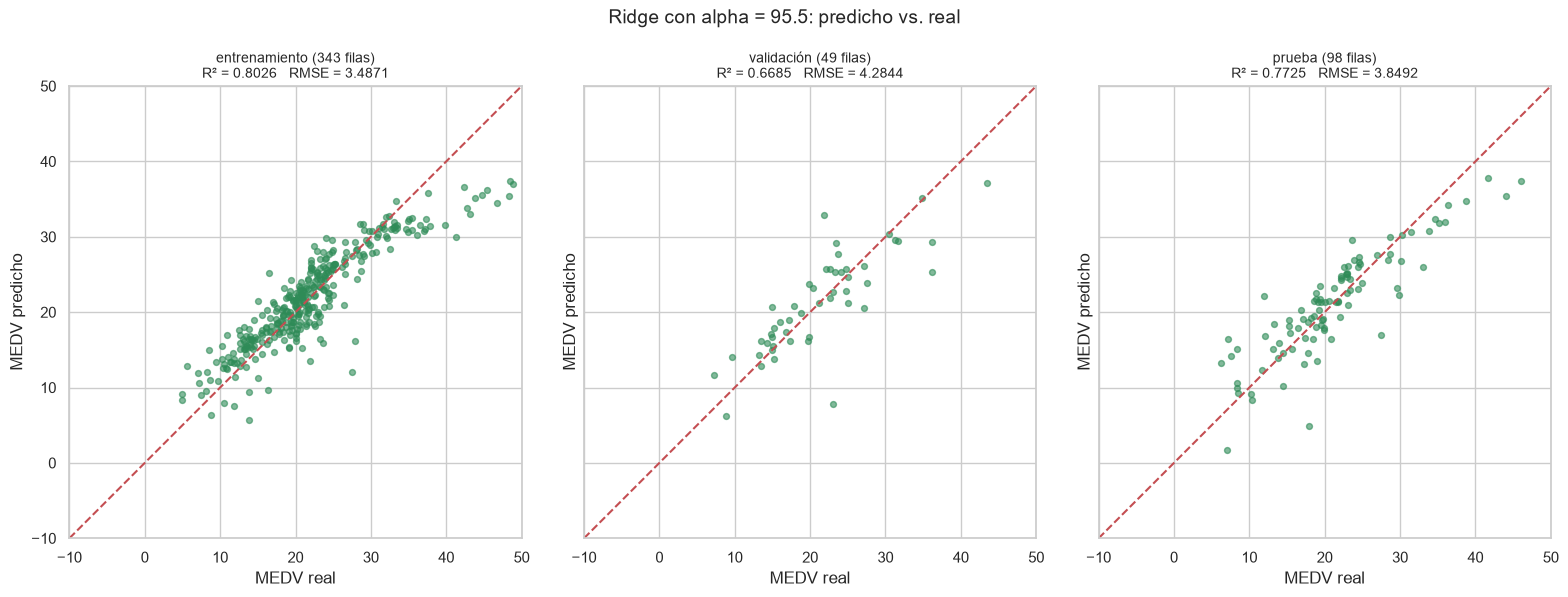

In [114]:
# El modelo elegido en los tres conjuntos, para ver si la nube se abre al pasar a datos que no vio
conjuntos_ridge = {"entrenamiento": (y_train, ridge_opt.predict(X_train_prep)),
                   "validación": (y_val, ridge_opt.predict(X_val_prep)),
                   "prueba": (y_test, ridge_opt.predict(X_test_prep))}
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)
for ax, (conjunto, (y_real, y_pred)) in zip(axes, conjuntos_ridge.items()):
    graficar_predicho_vs_real(ax, y_real, y_pred,
                              f"{conjunto} ({len(y_real)} filas)\n"
                              f"R² = {r2_score(y_real, y_pred):.4f}   RMSE = {root_mean_squared_error(y_real, y_pred):.4f}",
                              color="seagreen")
plt.suptitle(f"Ridge con alpha = {alpha_ridge:.1f}: predicho vs. real", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

*Figura 22. Ridge optimizado: valor predicho contra valor real en entrenamiento, validación y prueba. La línea discontinua es la predicción perfecta.*

La nube de prueba tiene un ancho parecido a la de entrenamiento: el modelo no se desarma con
viviendas que no vio, que es lo mismo que decía la caída moderada del R². Validación se ve
peor por un par de viviendas muy mal predichas (una de 23 mil que el modelo pone cerca de 8 y
otra de 22 que pone en 33), que en un conjunto de 49 filas pesan mucho.

En los tres conjuntos se repite lo mismo arriba a la derecha: las viviendas más caras quedan
por debajo de la diagonal. Se ve mejor en entrenamiento, que tiene más casos: de las que
valen más de 40 mil, el modelo no predice ninguna por encima de 38. Es la subestimación del
segmento caro que marcaban los residuos por tramo, y regularizar no la corrige.

In [115]:
# RMSE de prueba de LinearRegression con LSTAT sin transformar, sobre las mismas filas
escalador_sin_log = StandardScaler().fit(X_train)
lineal_sin_log = LinearRegression().fit(escalador_sin_log.transform(X_train), y_train)
print(f"LSTAT sin logaritmo: {root_mean_squared_error(y_test, lineal_sin_log.predict(escalador_sin_log.transform(X_test))):.4f}")
print(f"LSTAT con logaritmo: {resultados['LinearRegression']['RMSE']:.4f}")

LSTAT sin logaritmo: 4.2470
LSTAT con logaritmo: 3.8779


Con `LSTAT` sin transformar, el mismo `LinearRegression` da un RMSE de prueba de 4,2470 sobre
las mismas 98 filas, contra 3,8779 con el logaritmo. La transformación bajó el error un 9%, más
de doce veces lo que separa al mejor de los ocho modelos del peor (0,030).

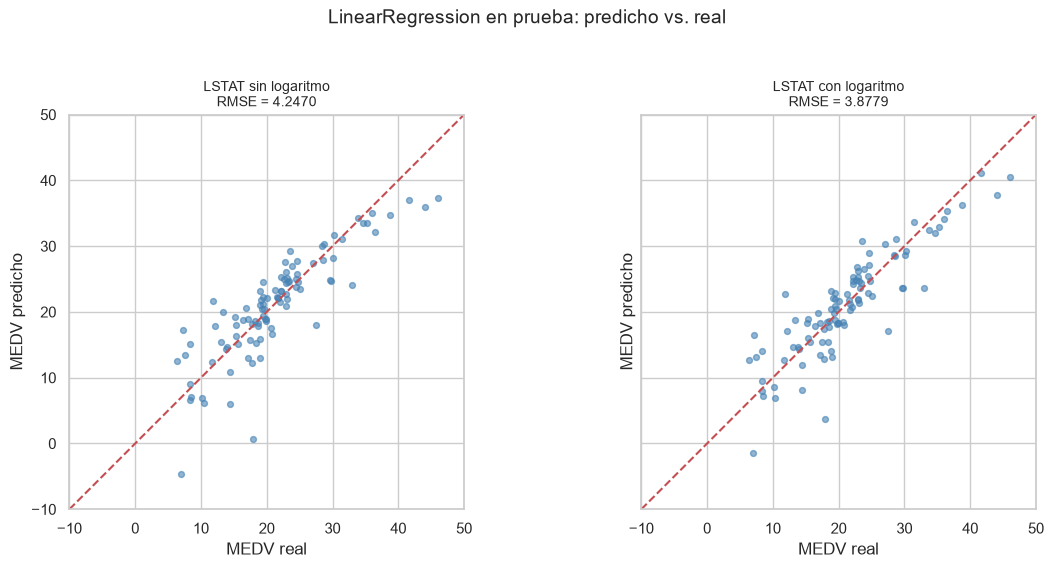

In [116]:
# Las mismas 98 viviendas de prueba, con LSTAT sin transformar y con logaritmo
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
pred_sin_log = lineal_sin_log.predict(escalador_sin_log.transform(X_test))
for ax, (titulo, y_pred) in zip(axes, {"LSTAT sin logaritmo": pred_sin_log,
                                       "LSTAT con logaritmo": pred_test}.items()):
    graficar_predicho_vs_real(ax, y_test, y_pred,
                              f"{titulo}\nRMSE = {root_mean_squared_error(y_test, y_pred):.4f}")
plt.suptitle("LinearRegression en prueba: predicho vs. real", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

*Figura 23. `LinearRegression` en prueba con `LSTAT` sin transformar (izquierda) y con logaritmo (derecha). La línea discontinua es la predicción perfecta.*

La diferencia está en las puntas, que es donde la relación con `LSTAT` era más curva. Sin el
logaritmo, las viviendas más caras quedan bastante más abajo de la diagonal (la de 46 mil se
predice en 37) y en la punta barata aparece una predicción de casi −5. Con el logaritmo las
caras se acercan a la diagonal (la misma de 46 mil pasa a 40) y la predicción negativa se
achica a −1,41. En el medio, entre 15 y 30 mil, los dos paneles son casi iguales.

# Conclusión

El modelo final explica el 77% de la variabilidad del precio sobre datos que no vio y se
equivoca en promedio 3.849 dólares, sobre viviendas de 20.900 de mediana. Es un error del
18%: sirve para estimar el orden de magnitud del precio de un barrio, no para tasar una
propiedad.

Lo que más movió ese número no fue el modelo sino las decisiones sobre los datos. Los diez
modelos que probamos quedaron a poco más del 8% entre sí, y ocho de ellos dentro del 1%, mientras que enderezar
`LSTAT` con un logaritmo bajó el RMSE de prueba de 4,25 a 3,88 sobre las mismas filas. Fue
la parte del trabajo donde había algo que ganar, y también la que más nos costó, porque no
había una función de scikit-learn que la resolviera: había que mirar los datos y decidir.

Dos de esas decisiones son las que más defenderíamos.

La primera es haber eliminado las 8 filas que parecían recuperables. Eran las que tenían
sólo uno o dos faltantes, las más fáciles de justificar como aprovechables, y descubrir que
`RAD` y `TAX` venían con decimales donde debían ser enteros fue lo que mostró que sus datos
presentes tampoco eran reales. Si las hubiéramos imputado habríamos metido ocho barrios
inventados con criminalidad extrema al conjunto de entrenamiento.

La segunda es haber sacado las 16 viviendas topeadas en 50. Es la decisión con la que más
dudamos, porque achica el alcance del modelo a viviendas de menos de 50 mil dólares y eso
hay que declararlo. Pero medir el error contra un valor que sabemos que no es el verdadero
no mide nada.

Sobre los métodos, el trabajo terminó confirmando lo que la teoría anticipaba en los tres
casos. El gradiente descendente llega al mismo mínimo que la fórmula cerrada cuando el paso
está bien elegido, y falla de dos maneras distintas cuando no: quedándose corto sin avisar,
o divirgiendo hasta `nan`. La regularización no mejoró la predicción de forma apreciable,
que era lo esperable en un modelo que sufre de sesgo y no de varianza, pero sí redujo a
menos de la mitad la volatilidad de los coeficientes, y bastante más que eso en `RAD` y
`TAX`, que eran los que el VIF había señalado. Y Lasso, en su mejor `alpha`, no descartó
ninguna variable.

Lo que quedó sin resolver es el sesgo. Los residuos por tramo siguen dibujando una U, así
que a la relación todavía le falta curvatura que un modelo lineal no puede darle, y el
modelo sigue pudiendo predecir precios negativos porque una recta no tiene forma de saber
que un precio tiene piso. Las dos cosas se atacarían con términos polinómicos o
interacciones, o transformando también la variable a predecir. Son caminos que se salen de
la regresión lineal múltiple que pide el trabajo, pero es ahí donde está lo que falta.